# Evaluación Sumativa 2 — Validación por remuestreo y simulación
## Dataset: *E-Commerce Shipping Data* (entregas atrasadas)

**MCDI501 - Estadística Computacional para la Toma de Decisiones**
Magíster en Ciencia de Datos e Inteligencia Artificial, Universidad Andrés Bello
Equipo: José Ignacio Rodríguez, Yerko Gallardo Miranda y Sebastián Rojas Araya

La Evaluación Sumativa 1 (S1) planteó la pregunta *¿qué características se asocian con el atraso y qué evidencia orienta una revisión operacional?* y recomendó auditar los 2.647 envíos con descuento mayor que 10, todos atrasados. Este cuaderno valida esa evidencia con métodos computacionales:

1. *bootstrap* de los cuatro parámetros de S1 y de la diferencia de peso;
2. pruebas de permutación de tres contrastes de S1;
3. intervalos *bootstrap* de cinco correlaciones con el atraso o entre sus predictores;
4. simulación Monte Carlo de lotes de envíos con los parámetros de S1;
5. *jackknife* y escenarios de sensibilidad a extremos, supuestos y composición;
6. una tabla de resultados validados con recomendaciones para la Evaluación Sumativa 3 (S3).

Cada sección explica qué aporta a la pregunta, aplica el método con al menos 10.000 réplicas, compara con S1 e interpreta el resultado.

**Notebook de validación completa.** `notebooks/sumativa_2_validacion_completa_grupo1.ipynb` aplica las mismas técnicas inferenciales a los 194 resultados de S1 y guarda sus salidas en `outputs/validacion_completa/`. Tal notebook es el respaldo de cobertura completa y se encuentra disponible en el repositorio.

## 0. Configuración, datos y semilla

Los datos se leen directamente desde S1 (`sumativa_1/data/raw/ecommerce_shipping.csv`) y se verifica su huella SHA-256 contra el registro de S1. Se usan los mismos nombres y la misma codificación: `entrega_atrasada = 1` indica atraso y `0`, entrega puntual.

In [42]:
from pathlib import Path
import hashlib
import json
import platform
import time

import numpy as np
import pandas as pd
import scipy
from scipy import stats
from IPython.display import display

# Raíz de la Sumativa 2: funciona al ejecutar desde el repositorio, sumativa_2/ o sus notebooks/
ubicacion = Path.cwd().resolve()
candidatas = [p for a in [ubicacion, *ubicacion.parents] for p in [a, a / 'sumativa_2']]
RAIZ = next((p for p in candidatas if (p / 'notebooks/sumativa_2_grupo1.ipynb').is_file()
             and (p / 'docs/registro_semilla.json').is_file()), None)
if RAIZ is None:
    raise FileNotFoundError('Ejecute desde el repositorio, sumativa_2/ o sus notebooks/.')
RAIZ_S1 = RAIZ.parent / 'sumativa_1'
DATOS = RAIZ_S1 / 'data/raw/ecommerce_shipping.csv'
TABLAS_S1 = RAIZ_S1 / 'outputs/tablas'
TABLAS = RAIZ / 'outputs/tablas'
FIGURAS = RAIZ / 'outputs/figuras'
for carpeta in (TABLAS, FIGURAS):
    carpeta.mkdir(parents=True, exist_ok=True)

# Integridad: el CSV debe ser el registrado en S1
registro_fuente = json.loads((RAIZ_S1 / 'docs/registro_fuente.json').read_text(encoding='utf-8'))
HUELLA_DATOS = hashlib.sha256(DATOS.read_bytes()).hexdigest()
assert HUELLA_DATOS in {registro_fuente['file']['sha256'], registro_fuente['file']['sha256_lf_normalized']}, \
    'El CSV no coincide con el registrado en S1.'

raw = pd.read_csv(DATOS, encoding='utf-8-sig')
NOMBRES = {
    'ID': 'id_envio', 'Warehouse_block': 'bloque_bodega', 'Mode_of_Shipment': 'modalidad_envio',
    'Customer_care_calls': 'llamadas_atencion', 'Customer_rating': 'calificacion_cliente',
    'Cost_of_the_Product': 'costo_producto', 'Prior_purchases': 'compras_previas',
    'Product_importance': 'importancia_producto', 'Gender': 'genero',
    'Discount_offered': 'descuento_ofrecido', 'Weight_in_gms': 'peso_gramos',
}
TARGET = 'entrega_atrasada'
df = raw.rename(columns=NOMBRES)
df[TARGET] = raw['Reached.on.Time_Y.N']

n = len(df)
n_atr, n_punt = int(df[TARGET].sum()), int((df[TARGET] == 0).sum())
assert (n, n_atr, n_punt) == (10_999, 6_563, 4_436), 'Los conteos no coinciden con S1.'
print(f'Datos: {DATOS.relative_to(RAIZ.parent).as_posix()} (SHA-256 {HUELLA_DATOS[:12]}…)')
print(f'{n:,} envíos | atrasados: {n_atr:,} | puntuales: {n_punt:,}'.replace(',', '.'))

Datos: sumativa_1/data/raw/ecommerce_shipping.csv (SHA-256 dcdc3fd8f050…)
10.999 envíos | atrasados: 6.563 | puntuales: 4.436


### Semilla y flujos aleatorios

La semilla proviene del pulso 1.053.589 de la cadena 2 del *beacon* de aleatoriedad de la Universidad de Chile, registrado antes de su publicación (`docs/protocolo_semilla.md`). De ella se derivan siete flujos independientes con `SeedSequence(SEMILLA).spawn(7)`, en el mismo orden que en el notebook de validación completa. Cada técnica usa su propio flujo, de modo que reejecutar una sección no altera las demás.

Toda la aleatoriedad del cuaderno usa la **semilla única** registrada según `docs/protocolo_semilla.md`, obtenida del *beacon* de aleatoriedad de la Universidad de Chile con una regla publicada antes de la emisión del pulso. Se lee desde `docs/registro_semilla.json`. De ella se derivan siete flujos independientes con `SeedSequence(SEMILLA).spawn(7)`, en el mismo orden que en el notebook de validación completa. Cada técnica usa su propio flujo, de modo que reejecutar una sección no altera las demás.

La verificación completa contra el *beacon* se ejecuta con `uv run python sumativa_2/scripts/semilla_beacon.py verificar`.

In [43]:
registro_semilla = json.loads((RAIZ / 'docs/registro_semilla.json').read_text(encoding='utf-8'))
SEMILLA = registro_semilla['semilla']
assert SEMILLA == int(registro_semilla['pulso']['outputValue'], 16) % 2**32, \
    'La semilla no corresponde al pulso registrado.'

FLUJOS = ['bootstrap_parametros', 'permutaciones', 'bootstrap_coeficientes', 'montecarlo_lotes',
          'montecarlo_empirico', 'sensibilidad_escenarios', 'sensibilidad_montecarlo']
SEMILLAS_FLUJO = dict(zip(FLUJOS, np.random.SeedSequence(SEMILLA).spawn(len(FLUJOS))))


def generador(flujo):
    # Generador nuevo del flujo indicado: reejecutar una sección reproduce sus mismos números
    return np.random.default_rng(SEMILLAS_FLUJO[flujo])


def subflujo(flujo, *clave):
    # Semilla hija y determinista de un flujo
    return np.random.SeedSequence(SEMILLA, spawn_key=tuple(SEMILLAS_FLUJO[flujo].spawn_key) + clave)


B = 10_000   # réplicas mínimas en todas las técnicas
print(f"SEMILLA = {SEMILLA} | pulso {registro_semilla['pulso']['uri']}")

SEMILLA = 1505514103 | pulso https://random.uchile.cl/beacon/2.1-beta/chain/2/pulse/1053589


In [44]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import FuncFormatter

# Convención de figuras: negro = referencia de S1; azul = resultado de S2;
# terracota = lo que se destaca (observado, alternativa, límite de alerta); gris punteado = umbrales
AZUL, TERRA, GRIS, VERDE = '#1f5f8b', '#d1603d', '#555555', '#41866a'
GRID = '#e1e4e8'
ANCHO = 6.3   # pulgadas: ancho de texto del informe
plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 300, 'savefig.bbox': 'tight', 'pdf.fonttype': 42,
    'figure.constrained_layout.use': True, 'font.family': 'serif', 'font.size': 9,
    'axes.titlesize': 9, 'axes.labelsize': 8.5, 'xtick.labelsize': 8, 'ytick.labelsize': 8,
    'legend.fontsize': 8, 'legend.frameon': False, 'axes.edgecolor': '#8c8578',
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.titlelocation': 'left',
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.6, 'axes.axisbelow': True,
})


def num(x, dec=0):
    # Número con formato es-CL: punto de miles y coma decimal
    return f'{x:,.{dec}f}'.replace(',', '_').replace('.', ',').replace('_', '.').replace('-', '−')


FMT_NUM = lambda dec: FuncFormatter(lambda x, _: num(x, dec))
FMT_PCT = FuncFormatter(lambda x, _: f'{num(x * 100, 0 if abs(x * 100 - round(x * 100)) < 1e-9 else 1)}%')


def guardar(nombre, fig):
    # Exporta en PDF (vectorial, para LaTeX) y PNG
    for ext in ('pdf', 'png'):
        fig.savefig(FIGURAS / f'{nombre}.{ext}')
    plt.show()

In [45]:
# Valores publicados en S1: son la referencia de cada comparación
def leer_s1(nombre, **kw):
    return pd.read_csv(TABLAS_S1 / nombre, float_precision='round_trip', **kw)


est_s1 = leer_s1('estimaciones.csv').set_index('variable')
contrastes_s1 = {c: leer_s1(f).iloc[0] for c, f in
                 [('T01', 'contraste_modalidad.csv'), ('T02', 'contraste_peso.csv'), ('T03', 'contraste_descuento.csv')]}
holm_s1 = leer_s1('contrastes_holm_7.csv').set_index('codigo')
cor_atraso_s1 = leer_s1('correlacion_dependiente_cuantitativas.csv').set_index('variable')
spearman_s1 = leer_s1('correlacion_spearman.csv', index_col=0)
segmento_s1 = leer_s1('segmento_descuento.csv').set_index('descuento_mayor_10')

USADAS_S1 = ['estimaciones.csv', 'contraste_modalidad.csv', 'contraste_peso.csv', 'contraste_descuento.csv',
             'contrastes_holm_7.csv', 'correlacion_dependiente_cuantitativas.csv', 'correlacion_spearman.csv',
             'segmento_descuento.csv']

HUELLAS_S1 = {f: hashlib.sha256((TABLAS_S1 / f).read_bytes().replace(b'\r\n', b'\n')).hexdigest() for f in USADAS_S1}

VERSIONES = dict(python=platform.python_version(), numpy=np.__version__, pandas=pd.__version__, scipy=scipy.__version__)
print(f'{len(USADAS_S1)} tablas de referencia de S1 leídas.')

8 tablas de referencia de S1 leídas.


## 1. Selección de resultados

La selección se basa en lo que sostiene la conclusión de S1, no en el valor *p* ni en el signo. Cada resultado responde una parte de la pregunta y justifica una técnica:

| Resultado de S1 | Qué aporta a la pregunta | Técnica en S2 | Criterio |
|---|---|---|---|
| Proporción de atraso, 59,67 % (IC de Wilson) | Dimensiona el problema | *Bootstrap* percentil y con corrección de sesgo y aceleración (BCa) | Parámetros |
| Peso, costo y llamadas medios (IC *t* de Student) | Caracterizan los envíos | *Bootstrap* percentil y BCa | Parámetros |
| Diferencia de peso medio, −896 g | Principal característica asociada al atraso | *Bootstrap* por grupo | Parámetros |
| Prueba *t* de Welch de peso medio entre envíos atrasados y puntuales (T02) | Asociación peso–atraso | Permutación | Pruebas |
| Prueba *t* de Welch de descuento medio entre envíos atrasados y puntuales (T03) | Base de la recomendación de auditoría | Permutación | Pruebas |
| Prueba χ² de independencia entre modalidad de envío y atraso (T01) | Contraste sin asociación: no respalda cambiar de transporte | Permutación | Pruebas |
| Correlaciones de descuento, peso, costo y compras previas con el atraso, y de descuento con peso | Qué variables conservar para S3 | IC *bootstrap* emparejado | Correlaciones |
| Proporción de atraso y segmento de descuento > 10 | Qué tasa de atraso esperar en un lote auditado | Monte Carlo | Simulación |
| Todo lo anterior | Si la conclusión depende de pocos envíos, de los extremos o del segmento de descuento | *Jackknife* y escenarios | Robustez |

## 2. Funciones de remuestreo y simulación

Todas las funciones están en este cuaderno. Reciben un generador externo, nunca crean uno propio, y trabajan por lotes para no reservar matrices de 10.000 × 10.999.

In [46]:
from scipy.stats import norm, rankdata


def bootstrap(estadistico, muestras, rng, B=B, lote=1_000):
    # Réplicas bootstrap. Una muestra: se remuestrean filas; varias: dentro de cada grupo (estratificado)
    muestras = [np.asarray(m) for m in muestras]
    replicas = []
    for inicio in range(0, B, lote):
        b = min(lote, B - inicio)
        remuestras = [m[rng.integers(0, len(m), size=(b, len(m)))] for m in muestras]
        replicas.append(np.asarray(estadistico(*remuestras)))
    return np.concatenate(replicas)


def jackknife(estadistico, muestras, lote=1_000):
    # Valores leave-one-out, en el orden de las muestras y de sus observaciones
    muestras = [np.asarray(m) for m in muestras]
    valores = []
    for g, m in enumerate(muestras):
        posiciones = np.arange(len(m) - 1)
        for inicio in range(0, len(m), lote):
            retiradas = np.arange(inicio, min(inicio + lote, len(m)))
            indices = posiciones[None, :] + (posiciones[None, :] >= retiradas[:, None])
            entradas = [np.broadcast_to(o, (len(retiradas), len(o))) for o in muestras]
            entradas[g] = m[indices]
            valores.append(np.asarray(estadistico(*entradas)))
    return np.concatenate(valores)


def intervalos_bootstrap(replicas, estimacion, valores_jk, tamanos=None, alfa=0.05):
    # Sesgo, EE, IC percentil y BCa; la aceleración se estima por jackknife, ponderando cada grupo
    rep = np.asarray(replicas, dtype=float)
    res = {'B': len(rep), 'sesgo': rep.mean() - estimacion, 'ee': rep.std(ddof=1),
           'ic_percentil_inf': np.quantile(rep, alfa / 2), 'ic_percentil_sup': np.quantile(rep, 1 - alfa / 2)}
    prop = (np.sum(rep < estimacion) + 0.5 * np.sum(rep == estimacion)) / len(rep)   # z0 con empates
    tamanos = [len(valores_jk)] if tamanos is None else list(tamanos)
    num_a = den_a = 0.0
    for v in np.split(np.asarray(valores_jk, dtype=float), np.cumsum(tamanos)[:-1]):
        u = (len(v) - 1) * (v.mean() - v)
        num_a += np.sum(u ** 3) / len(v) ** 3
        den_a += np.sum(u ** 2) / len(v) ** 2
    z0, a = norm.ppf(prop), num_a / (6 * den_a ** 1.5)
    z = norm.ppf([alfa / 2, 1 - alfa / 2])
    niveles = norm.cdf(z0 + (z0 + z) / (1 - a * (z0 + z)))
    res.update(z0=z0, aceleracion=a, ic_bca_inf=np.quantile(rep, niveles[0]), ic_bca_sup=np.quantile(rep, niveles[1]))
    return res

In [47]:
PRUEBAS = {'T01': 'Prueba χ² de independencia entre modalidad de envío y atraso',
           'T02': 'Prueba t de Welch de peso medio entre envíos atrasados y puntuales',
           'T03': 'Prueba t de Welch de descuento medio entre envíos atrasados y puntuales'}
VARIABLE_PRUEBA = {'T01': 'modalidad_envio', 'T02': 'peso_gramos', 'T03': 'descuento_ofrecido'}


def preparar_contraste(datos, codigo):
    # Etiquetas de atraso, función del estadístico y efecto
    y = datos[TARGET].to_numpy(dtype=int)
    if codigo == 'T01':
        categorias, _ = pd.factorize(datos['modalidad_envio'])
        totales = np.bincount(categorias).astype(float)
        esperados = np.column_stack((totales * (1 - y.mean()), totales * y.mean()))

        def estadistico(etiquetas):
            atrasos = np.bincount(categorias, weights=etiquetas, minlength=len(totales))
            observado = np.column_stack((totales - atrasos, atrasos))
            return np.sum((observado - esperados) ** 2 / esperados)
        return y, estadistico, dict(cola='superior', gl=2, efecto=np.sqrt(estadistico(y) / len(y)), nombre_efecto='V de Cramér')
    x = datos[VARIABLE_PRUEBA[codigo]].to_numpy(dtype=float)

    def estadistico(etiquetas):
        a, b = x[etiquetas == 1], x[etiquetas == 0]
        return (a.mean() - b.mean()) / np.sqrt(a.var(ddof=1) / len(a) + b.var(ddof=1) / len(b))
    a, b = x[y == 1], x[y == 0]
    va, vb = a.var(ddof=1) / len(a), b.var(ddof=1) / len(b)
    gl = (va + vb) ** 2 / (va ** 2 / (len(a) - 1) + vb ** 2 / (len(b) - 1))
    return y, estadistico, dict(cola='bilateral', gl=gl, efecto=a.mean() - b.mean(), nombre_efecto='diferencia de medias')


def permutar_contraste(datos, codigo, rng, B=B):
    # Permuta el atraso entre envíos (conserva los márgenes); p = (1 + excedencias) / (B + 1)
    y, estadistico, meta = preparar_contraste(datos, codigo)
    observado = float(estadistico(y))
    replicas = np.array([estadistico(rng.permutation(y)) for _ in range(B)])
    distancia, referencia = (replicas, observado) if meta['cola'] == 'superior' else (np.abs(replicas), abs(observado))
    excedencias = int(np.sum(distancia >= referencia * (1 - 1e-12)))   # empates numéricos cuentan como excedencia
    p_perm = (excedencias + 1) / (B + 1)
    p_param = (stats.chi2.sf(observado, meta['gl']) if meta['cola'] == 'superior'
               else 2 * stats.t.sf(abs(observado), meta['gl']))
    return dict(codigo=codigo, prueba=PRUEBAS[codigo], n=len(y), B=B, estadistico_observado=observado,
                efecto=meta['efecto'], nombre_efecto=meta['nombre_efecto'], gl=meta['gl'], excedencias=excedencias,
                p_perm=p_perm, mcse_p=np.sqrt(p_perm * (1 - p_perm) / B), p_parametrico=p_param,
                cola=meta['cola']), replicas

In [48]:
# Cinco correlaciones de S1: (id, variable x, variable y, coeficiente)
CORRELACIONES = [
    ('COR-1', 'descuento_ofrecido', TARGET, 'r punto-biserial'),
    ('COR-2', 'peso_gramos', TARGET, 'r punto-biserial'),
    ('COR-3', 'descuento_ofrecido', 'peso_gramos', 'ρ de Spearman'),
    ('COR-4', 'costo_producto', TARGET, 'r punto-biserial'),
    ('COR-5', 'compras_previas', TARGET, 'r punto-biserial'),
]
ETIQ = {'descuento_ofrecido': 'Descuento', 'peso_gramos': 'Peso', 'costo_producto': 'Costo',
        'compras_previas': 'Compras previas', 'llamadas_atencion': 'Llamadas', TARGET: 'Atraso'}


def _pearson(a, b):
    a = a - a.mean(axis=1, keepdims=True)
    b = b - b.mean(axis=1, keepdims=True)
    return (a * b).sum(axis=1) / np.sqrt((a * a).sum(axis=1) * (b * b).sum(axis=1))


def correlaciones_filas(datos, indices):
    # Cada fila de `indices` es una muestra de envíos; Spearman recalcula los rangos en cada una
    salida = np.empty((len(indices), len(CORRELACIONES)))
    for j, (_, x, y, coef) in enumerate(CORRELACIONES):
        a, b = datos[x].to_numpy(dtype=float)[indices], datos[y].to_numpy(dtype=float)[indices]
        if coef == 'ρ de Spearman':
            a, b = rankdata(a, axis=1), rankdata(b, axis=1)
        salida[:, j] = _pearson(a, b)
    return salida


def bootstrap_correlaciones(datos, rng, B=B, lote=50):
    # Bootstrap emparejado: las cinco correlaciones comparten las mismas filas remuestreadas
    return np.vstack([correlaciones_filas(datos, rng.integers(0, len(datos), size=(min(lote, B - i), len(datos))))
                      for i in range(0, B, lote)])


def jackknife_correlaciones(datos, lote=200):
    posiciones = np.arange(len(datos) - 1)
    return np.vstack([correlaciones_filas(datos, posiciones[None, :] + (posiciones[None, :] >= r[:, None]))
                      for r in np.array_split(np.arange(len(datos)), int(np.ceil(len(datos) / lote)))])

In [49]:
from scipy.stats import binom


def simular_lotes(p, N, B, rng):
    # Tasas de atraso K/N de B lotes, con K ~ Binomial(N, p)
    return rng.binomial(N, p, size=B) / N


def lotes_inversion(u, N, p):
    # Mismas uniformes u para distintos p: las diferencias entre escenarios se deben solo a p
    return binom.ppf(u, N, p) / N


def resumir_lotes(tasas, p, N, umbral=0.60):
    # Resumen simulado junto a los valores binomiales exactos; MCSE de la media y de la probabilidad
    tasas = np.asarray(tasas, dtype=float)
    q = (tasas > umbral).mean()
    res = {'N': N, 'B': len(tasas), 'p': p, 'media': tasas.mean(), 'de': tasas.std(ddof=1),
           'de_exacta': np.sqrt(p * (1 - p) / N),
           'q025': np.quantile(tasas, 0.025), 'q975': np.quantile(tasas, 0.975), 'q99': np.quantile(tasas, 0.99),
           'q99_exacto': binom.ppf(0.99, N, p) / N,
           'prob_sobre_umbral': q, 'prob_exacta': binom.sf(np.floor(umbral * N), N, p),
           'mcse_media': tasas.std(ddof=1) / np.sqrt(len(tasas)), 'mcse_prob': np.sqrt(q * (1 - q) / len(tasas))}
    res['dif_media'], res['dif_prob'] = res['media'] - p, q - res['prob_exacta']
    return res

## 3. *Bootstrap* de los parámetros

**Por qué.** S1 usó IC de Wilson para la proporción e IC *t* de Student para las medias. Ambos dependen de aproximaciones: la normal del estimador, y en el caso de *t*, una distribución que el peso (bimodal) y el costo no cumplen. El *bootstrap* no supone una forma para la población. Si sus intervalos coinciden con los de S1, la incertidumbre informada no depende de esas aproximaciones; si difieren, muestra en qué dirección y cuánto.

**Método.**

- B = 10.000 remuestras con reemplazo de los 10.999 envíos (flujo `bootstrap_parametros`).
- En la diferencia de peso se remuestrea dentro de cada grupo, conservando los 6.563 atrasados y los 4.436 puntuales
- IC percentil e IC BCa al 95 %. La aceleración se estima por *jackknife*.
- El BCa se valida contra `scipy.stats.bootstrap` con las mismas réplicas.

**Comparación.** Para cada IC se informa:

- el ancho relativo al IC de S1;
- el desplazamiento del centro, medido en errores estándar (EE);
- la asimetría de la distribución *bootstrap*, que indica si un intervalo simétrico es adecuado.

In [50]:
atraso = df[TARGET].to_numpy(dtype=float)
peso, costo, llamadas = (df[v].to_numpy(dtype=float) for v in ('peso_gramos', 'costo_producto', 'llamadas_atencion'))
media = lambda m: m.mean(axis=1)
dif_medias = lambda a, b: a.mean(axis=1) - b.mean(axis=1)
es_atr = atraso == 1
t02 = contrastes_s1['T02']

# (id, parámetro, unidad, estimador, muestras, posiciones de cada muestra en df, IC de S1, método de S1)
PARAMETROS = [
    ('PAR-1', 'Proporción de atraso', '%', media, (atraso,), (np.arange(n),),
     est_s1.loc[TARGET, ['ic_inf', 'ic_sup']].to_numpy(), 'Wilson'),
    ('PAR-2', 'Peso medio', 'g', media, (peso,), (np.arange(n),),
     est_s1.loc['peso_gramos', ['ic_inf', 'ic_sup']].to_numpy(), 't de Student'),
    ('PAR-3', 'Costo medio', 'USD', media, (costo,), (np.arange(n),),
     est_s1.loc['costo_producto', ['ic_inf', 'ic_sup']].to_numpy(), 't de Student'),
    ('PAR-4', 'Llamadas medias', 'llamadas', media, (llamadas,), (np.arange(n),),
     est_s1.loc['llamadas_atencion', ['ic_inf', 'ic_sup']].to_numpy(), 't de Student'),
    ('EFE-1', 'Diferencia de peso medio (atrasado − puntual)', 'g', dif_medias, (peso[es_atr], peso[~es_atr]),
     (np.flatnonzero(es_atr), np.flatnonzero(~es_atr)), np.array([t02['ic_inf'], t02['ic_sup']]), 't de Welch'),
]
VALOR_S1 = {'PAR-1': est_s1.loc[TARGET, 'estimacion'], 'PAR-2': est_s1.loc['peso_gramos', 'estimacion'],
            'PAR-3': est_s1.loc['costo_producto', 'estimacion'], 'PAR-4': est_s1.loc['llamadas_atencion', 'estimacion'],
            'EFE-1': t02['diferencia']}
# EE de S1; en la diferencia de peso se deduce del IC de Welch publicado
EE_S1 = {'PAR-1': est_s1.loc[TARGET, 'ee'], 'PAR-2': est_s1.loc['peso_gramos', 'ee'],
         'PAR-3': est_s1.loc['costo_producto', 'ee'], 'PAR-4': est_s1.loc['llamadas_atencion', 'ee'],
         'EFE-1': (t02['ic_sup'] - t02['ic_inf']) / (2 * stats.t.ppf(0.975, t02['gl']))}

rng = generador('bootstrap_parametros')
inicio = time.perf_counter()
REPLICAS, JACKKNIFE, filas = {}, {}, []
for id_, nombre, unidad, est, muestras, posiciones, ic_s1, metodo_s1 in PARAMETROS:
    original = float(est(*[m[None, :] for m in muestras])[0])
    assert np.isclose(original, VALOR_S1[id_], rtol=1e-12), f'{id_} no reproduce S1.'
    REPLICAS[id_] = bootstrap(est, muestras, rng)
    JACKKNIFE[id_] = (jackknife(est, muestras), np.concatenate(posiciones))
    res = intervalos_bootstrap(REPLICAS[id_], original, JACKKNIFE[id_][0], tamanos=[len(m) for m in muestras])
    ancho_s1 = ic_s1[1] - ic_s1[0]
    filas.append({'id': id_, 'parametro': nombre, 'unidad': unidad, 'estimacion_s1': original,
                  'metodo_s1': metodo_s1, 'ic_s1_inf': ic_s1[0], 'ic_s1_sup': ic_s1[1], **res,
                  'asimetria_replicas': stats.skew(REPLICAS[id_]),
                  'razon_ancho_percentil': (res['ic_percentil_sup'] - res['ic_percentil_inf']) / ancho_s1,
                  'razon_ancho_bca': (res['ic_bca_sup'] - res['ic_bca_inf']) / ancho_s1,
                  'desplazamiento_bca_ee': ((res['ic_bca_inf'] + res['ic_bca_sup']) - (ic_s1[0] + ic_s1[1])) / 2 / res['ee'],
                  'ee_s1': EE_S1[id_]})
bootstrap_parametros = pd.DataFrame(filas)
bootstrap_parametros['razon_ee'] = bootstrap_parametros['ee'] / bootstrap_parametros['ee_s1']
assert bootstrap_parametros['B'].ge(10_000).all()
bootstrap_parametros.to_csv(TABLAS / 'bootstrap_parametros.csv', index=False)
print(f'Bootstrap de {len(PARAMETROS)} estimandos, B = {num(B)}, en {num(time.perf_counter() - inicio, 1)} s.')
display(bootstrap_parametros[['id', 'parametro', 'estimacion_s1', 'metodo_s1', 'ic_s1_inf', 'ic_s1_sup',
                              'ic_percentil_inf', 'ic_percentil_sup', 'ic_bca_inf', 'ic_bca_sup']].round(4))
display(bootstrap_parametros[['id', 'sesgo', 'ee', 'ee_s1', 'razon_ee', 'razon_ancho_percentil', 'razon_ancho_bca',
                              'desplazamiento_bca_ee', 'z0', 'aceleracion', 'asimetria_replicas']].round(4))

Bootstrap de 5 estimandos, B = 10.000, en 5,4 s.


,id,parametro,estimacion_s1,metodo_s1,ic_s1_inf,ic_s1_sup,ic_percentil_inf,ic_percentil_sup,ic_bca_inf,ic_bca_sup
0,PAR-1,Proporción de atraso,0.5967,Wilson,0.5875,0.6058,0.5874,0.6058,0.5875,0.6059
1,PAR-2,Peso medio,3634.0167,t de Student,3603.4508,3664.5826,3602.0417,3664.6520,3602.7570,3665.2821
2,PAR-3,Costo medio,210.1968,t de Student,209.2985,211.0952,209.2932,211.0911,209.3138,211.1132
3,PAR-4,Llamadas medias,4.0545,t de Student,4.0331,4.0758,4.0336,4.0754,4.0337,4.0755
4,EFE-1,Diferencia de peso medio (atrasado − puntual),-896.0283,t de Welch,-956.0308,-836.0258,-955.4634,-836.6222,-955.4048,-836.5055


,id,sesgo,ee,ee_s1,razon_ee,razon_ancho_percentil,razon_ancho_bca,desplazamiento_bca_ee,z0,aceleracion,asimetria_replicas
0,PAR-1,-0.0000,0.0047,0.0047,0.9990,1.0018,1.0018,0.0072,0.0056,-0.0006,-0.0293
1,PAR-2,-0.3839,15.7644,15.5934,1.0110,1.0242,1.0228,0.0002,0.0273,-0.0004,-0.0398
2,PAR-3,-0.0044,0.4555,0.4583,0.9939,1.0007,1.0015,0.0365,0.0172,-0.0002,0.0047
3,PAR-4,-0.0001,0.0107,0.0109,0.9875,0.9781,0.9780,0.0127,0.0006,0.0006,-0.0023
4,EFE-1,-0.2956,30.5689,30.6102,0.9987,0.9903,0.9908,0.0024,0.0003,0.0011,0.0009


In [51]:
# Validación del BCa: scipy recibe las mismas réplicas; solo cambia la implementación del jackknife y del BCa
def bca_scipy(est, muestras, replicas):
    def estadistico(*m, axis=-1):
        m = [np.moveaxis(x, axis, -1) for x in m]
        return np.asarray(est(*[x.reshape(-1, x.shape[-1]) for x in m])).reshape(m[0].shape[:-1])
    previo = type('Previo', (), {'bootstrap_distribution': replicas})()
    ic = stats.bootstrap(muestras, estadistico, n_resamples=0, method='BCa', vectorized=True,
                         bootstrap_result=previo).confidence_interval
    return ic.low, ic.high


for id_, _, _, est, muestras, *_ in PARAMETROS:
    propio = bootstrap_parametros.set_index('id').loc[id_, ['ic_bca_inf', 'ic_bca_sup']].to_numpy(dtype=float)
    np.testing.assert_allclose(propio, bca_scipy(est, muestras, REPLICAS[id_]), rtol=1e-10)
print('BCa propio = BCa de scipy.stats.bootstrap en los cinco estimandos (tolerancia relativa 1e-10).')

BCa propio = BCa de scipy.stats.bootstrap en los cinco estimandos (tolerancia relativa 1e-10).


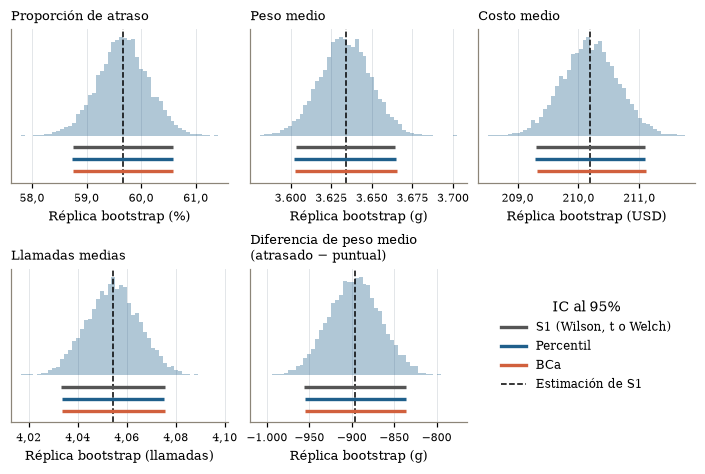

In [52]:
fig, ejes = plt.subplots(2, 3, figsize=(ANCHO, 4.2))

ESTILO_IC = [('S1 (Wilson, t o Welch)', 'ic_s1', GRIS), ('Percentil', 'ic_percentil', AZUL), ('BCa', 'ic_bca', TERRA)]

for ax, (id_, nombre, unidad, *_) in zip(ejes.flat, PARAMETROS):
    fila = bootstrap_parametros.set_index('id').loc[id_]
    escala = 100 if unidad == '%' else 1
    alturas, _, _ = ax.hist(REPLICAS[id_] * escala, bins=50, color=AZUL, alpha=0.35, density=True)
    tope = alturas.max()
    ax.axvline(fila['estimacion_s1'] * escala, color='black', lw=1, ls='--')
    for j, (_, prefijo, color) in enumerate(ESTILO_IC):
        ax.hlines(-tope * (0.12 + 0.12 * j), fila[f'{prefijo}_inf'] * escala, fila[f'{prefijo}_sup'] * escala,
                  color=color, lw=2.2)
    ax.set_ylim(-tope * 0.48, tope * 1.08)
    ax.set_yticks([])
    ax.set_title(nombre.replace(' (atrasado − puntual)', '\n(atrasado − puntual)'), fontsize=8.5)
    ax.set_xlabel(f'Réplica bootstrap ({unidad})')
    dec = 1 if unidad in ('%', 'USD') else 2 if unidad == 'llamadas' else 0
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _, d=dec: num(v, d)))
    ax.tick_params(axis='x', labelsize=7)
leyenda = ejes.flat[-1]
leyenda.axis('off')
leyenda.legend([Line2D([], [], color=c, lw=2.2) for *_, c in ESTILO_IC] + [Line2D([], [], color='black', lw=1, ls='--')],
               [e for e, *_ in ESTILO_IC] + ['Estimación de S1'], loc='center', title='IC al 95%')

guardar('fig_1_bootstrap_parametros', fig)

#### Interpretación del *bootstrap*

**Los IC de S1 se confirman.** En los cinco estimandos, los IC percentil y BCa coinciden con los de S1 hasta la primera cifra decimal relevante:

| Estimando | IC de S1 | IC BCa | Ancho BCa / S1 |
|---|---|---|---:|
| Proporción de atraso | Wilson [58,75 %; 60,58 %] | [58,75 %; 60,59 %] | 1,002 |
| Peso medio | *t* [3.603,5; 3.664,6] g | [3.602,8; 3.665,3] g | 1,023 |
| Costo medio | *t* [209,30; 211,10] USD | [209,31; 211,11] USD | 1,002 |
| Llamadas medias | *t* [4,033; 4,076] | [4,034; 4,076] | 0,978 |
| Diferencia de peso | Welch [−956,0; −836,0] g | [−955,4; −836,5] g | 0,991 |

Las diferencias de ancho no superan el 2,3 %, y el centro del BCa se desplaza a lo sumo 0,04 EE respecto del IC de S1. El EE *bootstrap* difiere del analítico en menos de 1,3 %.

**Por qué no hay discrepancias.** La distribución *bootstrap* de las cinco estimaciones es simétrica (asimetría entre −0,04 y 0,005). Por eso la corrección de sesgo ($|z_0| \le 0{,}027$) y la aceleración ($|a| \le 0{,}0011$) son despreciables, y el BCa casi no se aparta del percentil. Aunque el peso es bimodal y el descuento muy asimétrico, con 10.999 envíos (o 4.436 en el grupo más pequeño) el teorema central del límite hace normal la distribución de la media. Los supuestos de forma de S1 no comprometían sus IC. El *bootstrap* muestra que esto vale **para estos tamaños**: en segmentos pequeños, como los 948 envíos de importancia alta, la conclusión podría cambiar.

**Lo que el *bootstrap* no corrige.** Remuestrear envíos supone que son independientes e idénticamente distribuidos, igual que S1. Si los atrasos se agrupan por bodega, período o lote de registros (ver 7.1), ambos métodos subestiman la incertidumbre por igual, y su coincidencia no lo revela.

## 4. Pruebas de permutación

**Por qué.** Los valores *p* de S1 suponen que el estadístico sigue una distribución de referencia (*t* de Welch o χ²). La permutación construye esa distribución con los propios datos: si el atraso no se asociara con el peso, el descuento o la modalidad, cualquier reasignación de las etiquetas de atraso entre los envíos sería igual de probable. Se eligen tres contrastes:

- T02, la prueba *t* de Welch de peso medio, es la asociación central de S1;
- T03, la prueba *t* de Welch de descuento medio, sostiene la recomendación de auditar el descuento alto, y su *p* paramétrico se representó como 0 por subdesbordamiento;
- T01, la prueba χ² de independencia entre modalidad de envío y atraso, es el único contraste sin evidencia de asociación y muestra cómo se comporta el método cuando la hipótesis nula es plausible.

**Método.**

- B = 10.000 permutaciones del atraso entre los envíos, que conservan los tamaños de los grupos (flujo `permutaciones`, en el orden T01, T02, T03).
- Se usa el mismo estadístico de S1, con *t* de Welch studentizado, más robusto ante varianzas distintas.
- $p_{perm} = (1 + \#\{|T^*| \ge |T_{obs}|\}) / (B + 1)$, bilateral para Welch y de cola superior para χ².
- Su error estándar Monte Carlo (MCSE) es $\sqrt{p(1-p)/B}$.
- Sin excedencias, $p_{perm} = 1/10.001$ es una **cota de resolución**, no una estimación del *p*.
- S1 controló la multiplicidad con Holm sobre siete pruebas. Como cota conservadora se informa $\min(1, 7\,p_{perm})$ (Bonferroni), que es siempre mayor o igual que el *p* de Holm.

In [ ]:
rng_perm = generador('permutaciones')
inicio = time.perf_counter()
filas, NULAS = [], {}

for codigo in ('T01', 'T02', 'T03'):
    resumen, NULAS[codigo] = permutar_contraste(df, codigo, rng_perm)
    s1 = contrastes_s1[codigo]
    np.testing.assert_allclose(resumen['estadistico_observado'], s1['chi2' if codigo == 'T01' else 't'], rtol=1e-10)
    nula = NULAS[codigo]
    if resumen['cola'] == 'superior':
        q_perm, q_teo = np.quantile(nula, 0.95), stats.chi2.ppf(0.95, resumen['gl'])
    else:
        q_perm, q_teo = np.quantile(np.abs(nula), 0.95), stats.t.ppf(0.975, resumen['gl'])
    filas.append({**resumen, 'p_s1': holm_s1.loc[codigo, 'p'], 'p_s1_holm7': holm_s1.loc[codigo, 'p_holm'],
                  'cota_bonferroni7_perm': min(1.0, 7 * resumen['p_perm']),
                  'critico_perm_95': q_perm, 'critico_teorico_95': q_teo,
                  'de_nula': nula.std(ddof=1), 'media_nula': nula.mean()})

permutaciones = pd.DataFrame(filas)
permutaciones['rechaza_s1'] = permutaciones['p_s1_holm7'] <= 0.05
permutaciones['rechaza_perm'] = permutaciones['cota_bonferroni7_perm'] <= 0.05
permutaciones['concordancia'] = permutaciones['rechaza_s1'] == permutaciones['rechaza_perm']
assert permutaciones['B'].ge(10_000).all() and permutaciones['p_perm'].between(1 / (B + 1), 1).all()

permutaciones.to_csv(TABLAS / 'permutaciones.csv', index=False)

pd.DataFrame(NULAS).rename_axis('permutacion').to_csv(TABLAS / 'permutaciones_nulas.csv')
print(f'Tres pruebas, B = {num(B)} permutaciones cada una, {num(time.perf_counter() - inicio, 1)} s.')

display(permutaciones[['codigo', 'estadistico_observado', 'efecto', 'excedencias', 'p_perm', 'mcse_p',
                       'p_parametrico', 'p_s1', 'p_s1_holm7', 'cota_bonferroni7_perm', 'concordancia']])
display(permutaciones[['codigo', 'media_nula', 'de_nula', 'critico_perm_95', 'critico_teorico_95']].round(4))


Tres pruebas, B = 10.000 permutaciones cada una, 7,2 s.


,codigo,estadistico_observado,efecto,excedencias,p_perm,mcse_p,p_parametrico,p_s1,p_s1_holm7,cota_bonferroni7_perm,concordancia
0,T01,0.743436,0.008221,6911,0.691131,0.00462,6.895488e-01,6.895488e-01,6.895488e-01,1.0000,True
1,T02,-29.272229,-896.028291,0,0.000100,0.00010,1.930930e-180,1.930930e-180,9.654651e-180,0.0007,True
2,T03,54.702867,13.117733,0,0.000100,0.00010,0.000000e+00,0.000000e+00,0.000000e+00,0.0007,True


,codigo,media_nula,de_nula,critico_perm_95,critico_teorico_95
0,T01,2.0206,2.0330,6.1035,5.9915
1,T02,-0.0085,0.9992,1.9367,1.9602
2,T03,-0.0006,1.0072,1.9662,1.9603


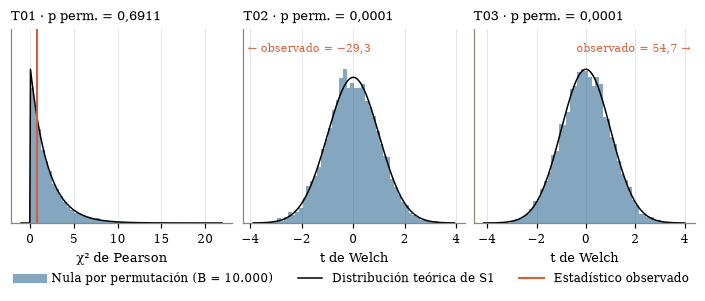

In [54]:
fig, ejes = plt.subplots(1, 3, figsize=(ANCHO, 2.4))
for ax, fila in zip(ejes, permutaciones.to_dict('records')):
    nula = NULAS[fila['codigo']]
    ax.hist(nula, bins=50, density=True, color=AZUL, alpha=0.55, label='Nula por permutación')
    rejilla_x = np.linspace(*ax.get_xlim(), 300)
    if fila['cola'] == 'superior':
        ax.plot(rejilla_x, stats.chi2.pdf(rejilla_x, fila['gl']), color='black', lw=1, label='χ²(2) teórica')
    else:
        ax.plot(rejilla_x, stats.t.pdf(rejilla_x, fila['gl']), color='black', lw=1, label='t teórica')
    obs = fila['estadistico_observado']
    limite = ax.get_xlim()
    ax.set_ylim(0, ax.get_ylim()[1] * 1.2)   # espacio para el rótulo del observado
    if limite[0] <= obs <= limite[1]:
        ax.axvline(obs, color=TERRA, lw=1.4, label='Observado')
    else:   # el estadístico observado queda fuera de la escala de la nula
        derecha = obs > 0
        ax.text(0.98 if derecha else 0.02, 0.93,
                f'observado = {num(obs, 1)} →' if derecha else f'← observado = {num(obs, 1)}',
                transform=ax.transAxes, ha='right' if derecha else 'left', va='top', color=TERRA, fontsize=7.5)
    ax.set_title(f"{fila['codigo']} · p perm. = {num(fila['p_perm'], 4)}", fontsize=8.5)
    ax.set_xlabel('χ² de Pearson' if fila['cola'] == 'superior' else 't de Welch')
    ax.set_yticks([])
handles = [Line2D([], [], color=AZUL, lw=6, alpha=0.55), Line2D([], [], color='black', lw=1),
           Line2D([], [], color=TERRA, lw=1.4)]
fig.legend(handles, ['Nula por permutación (B = 10.000)', 'Distribución teórica de S1', 'Estadístico observado'],
           loc='lower center', ncol=3, bbox_to_anchor=(0.5, -0.1))
guardar('fig_2_permutaciones', fig)

#### Interpretación de las permutaciones

| Prueba | Estadístico | *p* de permutación | *p* paramétrico (S1) | Decisión |
|---|---:|---:|---:|---|
| T01 | χ² = 0,743 | 0,691 (MCSE 0,005) | 0,690 | No se rechaza la hipótesis nula, en ambos métodos |
| T02 | *t* = −29,27 | ≤ 1/10.001 (0 excedencias) | 1,9 · 10⁻¹⁸⁰ | Se rechaza, en ambos métodos |
| T03 | *t* = 54,70 | ≤ 1/10.001 (0 excedencias) | 0 (subdesbordamiento) | Se rechaza, en ambos métodos |

**Concordancia.** Las tres decisiones coinciden con S1, también al ajustar por las siete pruebas: la cota de Bonferroni del *p* de permutación es 0,0007 en T02 y T03, y 1 en T01. En T01, los dos *p* difieren en 0,0016, menos de un MCSE.

**La distribución de referencia es correcta.** Las distribuciones nulas por permutación coinciden con las teóricas de S1 (figura 2):

- en T02 y T03, la nula tiene media cercana a 0 y desviación estándar (DE) de 1,00 y 1,01, y su valor crítico al 95 % (1,94 y 1,97) es casi el de la *t* (1,96);
- en T01, el crítico por permutación (6,10) es cercano al de χ²(2) (5,99).

Esto valida empíricamente la aproximación de S1, incluso en T03, cuyo descuento tiene DE de 19,1 en atrasados y 2,9 en puntuales.

**Qué enfoque es más apropiado.** La permutación no supone normalidad ni una forma de la distribución, por lo que es la validación más robusta de la **decisión**. Su resolución está limitada por B: con 10.000 permutaciones no distingue un *p* de 10⁻⁵ de uno de 10⁻¹⁸⁰. Para T02 y T03 conviene informar la decisión con la permutación y la **magnitud** con el *p* paramétrico, ya validado. Al estudentizar con Welch, la permutación es robusta también a varianzas distintas. Ninguno de los dos métodos corrige una posible dependencia entre envíos.

## 5. Correlaciones con IC *bootstrap*

**Por qué.** S1 publicó correlaciones con su valor *p*, pero sin un IC. Con 10.999 envíos casi cualquier correlación resulta significativa. Lo relevante para S3 es su **magnitud** y su **estabilidad**. Se seleccionan cinco:

- las dos asociaciones fuertes con el atraso: descuento (r punto-biserial 0,397) y peso (−0,269);
- la relación entre esos dos predictores (descuento–peso, ρ de Spearman −0,316), que indica si sus asociaciones con el atraso se confunden;
- dos asociaciones débiles: costo (−0,074) y compras previas (−0,056). Sirven para distinguir una correlación pequeña, pero precisa, de una inestable.

**Método.** *Bootstrap* emparejado con B = 10.000 (flujo `bootstrap_coeficientes`): las cinco correlaciones se recalculan sobre las mismas filas remuestreadas, y en Spearman los rangos se recalculan en cada réplica. Para cada una se informa el IC percentil al 95 %, si incluye el cero, el EE y la variabilidad relativa (EE/|r|).

In [55]:
VALOR_COR_S1 = {'COR-1': cor_atraso_s1.loc['descuento_ofrecido', 'r_punto_biserial'],
                'COR-2': cor_atraso_s1.loc['peso_gramos', 'r_punto_biserial'],
                'COR-3': spearman_s1.loc['descuento_ofrecido', 'peso_gramos'],
                'COR-4': cor_atraso_s1.loc['costo_producto', 'r_punto_biserial'],
                'COR-5': cor_atraso_s1.loc['compras_previas', 'r_punto_biserial']}
observadas = correlaciones_filas(df, np.arange(n)[None, :])[0]
np.testing.assert_allclose(observadas, list(VALOR_COR_S1.values()), rtol=1e-10)

inicio = time.perf_counter()
REPLICAS_COR = bootstrap_correlaciones(df, generador('bootstrap_coeficientes'))
filas = []
for j, (id_, x, y, coef) in enumerate(CORRELACIONES):
    rep = REPLICAS_COR[:, j]
    inf, sup = np.quantile(rep, [0.025, 0.975])
    filas.append({'id': id_, 'relacion': f'{ETIQ[x]} – {ETIQ[y]}', 'coeficiente': coef, 'estimacion_s1': observadas[j],
                  'B': len(rep), 'sesgo': rep.mean() - observadas[j], 'ee': rep.std(ddof=1), 'ic_inf': inf, 'ic_sup': sup,
                  'ancho_ic': sup - inf, 'incluye_cero': bool(inf <= 0 <= sup),
                  'variabilidad_relativa': rep.std(ddof=1) / abs(observadas[j])})
correlaciones = pd.DataFrame(filas)
assert correlaciones['B'].ge(10_000).all() and correlaciones[['ic_inf', 'ic_sup']].abs().le(1).all().all()
correlaciones.to_csv(TABLAS / 'correlaciones_bootstrap.csv', index=False)
print(f'Cinco correlaciones, B = {num(B)} remuestras emparejadas, {num(time.perf_counter() - inicio, 1)} s.')
display(correlaciones.drop(columns='B').round(4))

Cinco correlaciones, B = 10.000 remuestras emparejadas, 27,7 s.


,id,relacion,coeficiente,estimacion_s1,sesgo,ee,ic_inf,ic_sup,ancho_ic,incluye_cero,variabilidad_relativa
0,COR-1,Descuento – Atraso,r punto-biserial,0.3971,0.0000,0.0047,0.3879,0.4065,0.0186,False,0.0118
1,COR-2,Peso – Atraso,r punto-biserial,-0.2688,-0.0000,0.0092,-0.2867,-0.2509,0.0358,False,0.0341
2,COR-3,Descuento – Peso,ρ de Spearman,-0.3157,0.0001,0.0087,-0.3327,-0.2984,0.0343,False,0.0276
3,COR-4,Costo – Atraso,r punto-biserial,-0.0736,-0.0000,0.0095,-0.0924,-0.0549,0.0375,False,0.1294
4,COR-5,Compras previas – Atraso,r punto-biserial,-0.0555,-0.0002,0.0096,-0.0746,-0.0374,0.0372,False,0.1726


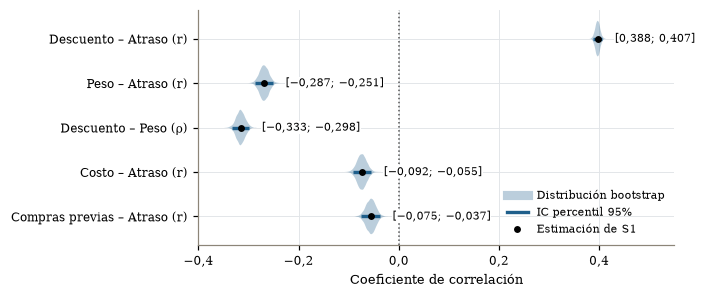

In [15]:
fig, ax = plt.subplots(figsize=(ANCHO, 2.6))
posiciones = np.arange(len(correlaciones))[::-1]
partes = ax.violinplot([REPLICAS_COR[:, j] for j in range(len(correlaciones))], positions=posiciones,
                       orientation='horizontal', widths=0.8, showextrema=False)
for cuerpo in partes['bodies']:
    cuerpo.set_facecolor(AZUL)
    cuerpo.set_alpha(0.3)
for pos, fila in zip(posiciones, correlaciones.to_dict('records')):
    ax.hlines(pos, fila['ic_inf'], fila['ic_sup'], color=AZUL, lw=2.2)
    ax.plot(fila['estimacion_s1'], pos, 'o', color='black', ms=3.5)
    ax.text(fila['ic_sup'] + 0.025, pos, f"[{num(fila['ic_inf'], 3)}; {num(fila['ic_sup'], 3)}]",
            va='center', fontsize=7, bbox=dict(facecolor='white', edgecolor='none', pad=0.5))
ax.axvline(0, color=GRIS, ls=':', lw=1)
ax.set_yticks(posiciones, [f"{f['relacion']} ({'ρ' if f['coeficiente'].startswith('ρ') else 'r'})"
                           for f in correlaciones.to_dict('records')])
ax.set_xlim(-0.4, 0.55)
ax.set_xlabel('Coeficiente de correlación')
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: num(v, 1)))
ax.legend([Line2D([], [], color=AZUL, lw=6, alpha=0.3), Line2D([], [], color=AZUL, lw=2.2),
           Line2D([], [], color='black', marker='o', ls='', ms=3.5)],
          ['Distribución bootstrap', 'IC percentil 95%', 'Estimación de S1'], loc='lower right', fontsize=7)
guardar('fig_3_correlaciones', fig)

#### Interpretación de las correlaciones

| Relación | Coeficiente | IC *bootstrap* 95 % | EE / \|r\| |
|---|---:|---|---:|
| Descuento – atraso | r = 0,397 | [0,388; 0,407] | 1,2 % |
| Peso – atraso | r = −0,269 | [−0,287; −0,251] | 3,4 % |
| Descuento – peso | ρ = −0,316 | [−0,333; −0,298] | 2,8 % |
| Costo – atraso | r = −0,074 | [−0,092; −0,055] | 12,9 % |
| Compras previas – atraso | r = −0,056 | [−0,075; −0,037] | 17,3 % |

**Ninguna incluye el cero con los datos completos.** Los IC miden entre 0,019 y 0,037 de ancho y la distribución *bootstrap* es simétrica, sin sesgo apreciable (≤ 0,0002). Con 10.999 envíos, todas las correlaciones se estiman con precisión absoluta, incluso las débiles.

**Precisión no equivale a estabilidad.** El IC solo describe la variabilidad muestral. Las correlaciones de costo y compras previas tienen una variabilidad relativa de 13 % a 17 % y explican menos del 0,6 % de la varianza del atraso ($r^2$). Su signo está determinado, pero su importancia práctica es mínima. La sección 7.2 muestra que la estabilidad real depende de qué envíos se incluyen: solo la correlación peso–atraso conserva su IC lejos del cero en todos los escenarios.

**Descuento y peso no son independientes** (ρ = −0,316): los envíos con más descuento son más livianos. Parte de la asociación de cada uno con el atraso podría deberse al otro, por lo que S3 debería modelarlos en conjunto.

## 6. Simulación Monte Carlo de lotes auditados

**Escenario.** S1 recomienda una revisión operacional. En la práctica, esa revisión examina **lotes** de envíos, como los de una semana o una bodega, y compara su tasa de atraso con la de referencia. Para interpretar el resultado de un lote se necesita saber cuánto varía su tasa **solo por azar** si el proceso es el mismo de S1:

- ¿Qué rango de tasas cabe esperar en lotes de 100, 500, 1.000 y 5.000 envíos?
- ¿Con qué probabilidad un lote supera el 60 % de atrasos sin que el proceso haya cambiado? El umbral de 60 % se usa por ser el entero más cercano sobre la tasa de S1 (59,67 %); es ilustrativo, no un objetivo de la empresa.
- ¿Desde qué tasa un lote es inusual, es decir, cuál es el percentil 99, que sirve como límite de alerta?

**Parámetros (solo de S1).** $p = 6.563/10.999 = 0{,}5967$, la proporción de atraso de S1. El análisis de sensibilidad (7.3) usa además su IC de Wilson y las tasas de los segmentos de descuento.

**Modelo.**

- Cada lote tiene $K \sim \text{Binomial}(N, p)$ atrasos, es decir, envíos independientes con la misma probabilidad de atraso.
- B = 10.000 lotes por tamaño (flujo `montecarlo_lotes`).
- La convergencia se verifica con el MCSE y con la media y la probabilidad acumuladas.
- Las tolerancias se fijan antes de ejecutar: $\text{MCSE}_{media} \le 0{,}001$ y $\text{MCSE}_{prob} \le 0{,}005$.
- La binomial exacta sirve como control de la simulación, no como sustituto: la sección 7.3 cambia el modelo, por ejemplo con dos segmentos, y allí la solución exacta ya no es inmediata.

In [56]:
P_S1 = n_atr / n
assert np.isclose(P_S1, est_s1.loc[TARGET, 'estimacion'], rtol=1e-12), 'p no coincide con S1.'
TAMANOS, UMBRAL = (100, 500, 1_000, 5_000), 0.60
TOL_MCSE_MEDIA, TOL_MCSE_PROB = 0.001, 0.005

rng_mc = generador('montecarlo_lotes')
inicio = time.perf_counter()
TASAS = {N: simular_lotes(P_S1, N, B, rng_mc) for N in TAMANOS}   # orden fijo de tamaños
montecarlo = pd.DataFrame([resumir_lotes(TASAS[N], P_S1, N, UMBRAL) for N in TAMANOS])
montecarlo['cumple_tolerancia'] = (montecarlo['mcse_media'] <= TOL_MCSE_MEDIA) & (montecarlo['mcse_prob'] <= TOL_MCSE_PROB)

convergencia = pd.DataFrame([{'N': N, 'B_parcial': b, 'media': TASAS[N][:b].mean(),
                              'prob_sobre_umbral': (TASAS[N][:b] > UMBRAL).mean(),
                              'mcse_prob': np.sqrt((q := (TASAS[N][:b] > UMBRAL).mean()) * (1 - q) / b)}
                             for N in TAMANOS for b in (100, 500, 1_000, 2_000, 5_000, 10_000)])

# Controles de coherencia del simulador
assert montecarlo['B'].ge(10_000).all() and montecarlo['cumple_tolerancia'].all()
assert (montecarlo['dif_media'].abs() <= 4 * montecarlo['mcse_media']).all()
assert (montecarlo['dif_prob'].abs() <= 4 * montecarlo['mcse_prob']).all()
montecarlo.to_csv(TABLAS / 'montecarlo_lotes.csv', index=False)
convergencia.to_csv(TABLAS / 'montecarlo_convergencia.csv', index=False)
print(f'Monte Carlo: p = {num(P_S1, 4)}, {len(TAMANOS)} tamaños, B = {num(B)} lotes por tamaño, '
      f'{num(time.perf_counter() - inicio, 2)} s. Tolerancias de MCSE cumplidas.')
display(montecarlo[['N', 'media', 'de', 'de_exacta', 'q025', 'q975', 'q99', 'q99_exacto', 'prob_sobre_umbral',
                    'prob_exacta', 'mcse_media', 'mcse_prob']].round(4))

Monte Carlo: p = 0,5967, 4 tamaños, B = 10.000 lotes por tamaño, 0,01 s. Tolerancias de MCSE cumplidas.


,N,media,de,de_exacta,q025,q975,q99,q99_exacto,prob_sobre_umbral,prob_exacta,mcse_media,mcse_prob
0,100,0.5970,0.0491,0.0491,0.500,0.6900,0.7100,0.7100,0.4360,0.4353,0.0005,0.0050
1,500,0.5968,0.0218,0.0219,0.554,0.6400,0.6480,0.6480,0.4207,0.4233,0.0002,0.0049
2,1000,0.5966,0.0155,0.0155,0.566,0.6270,0.6330,0.6330,0.3980,0.4038,0.0002,0.0049
3,5000,0.5967,0.0069,0.0069,0.583,0.6106,0.6132,0.6128,0.3106,0.3118,0.0001,0.0046


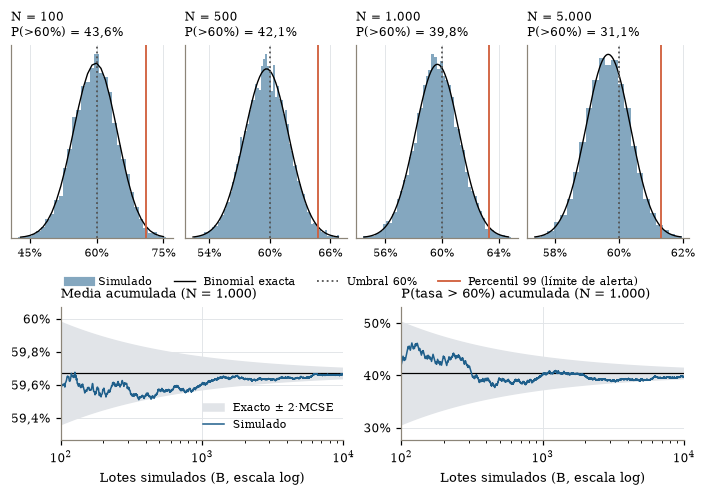

,N,B_parcial,media,prob_sobre_umbral,mcse_prob
12,1000,100,0.5958,0.4200,0.0494
13,1000,500,0.5957,0.3920,0.0218
14,1000,1000,0.5961,0.4020,0.0155
15,1000,2000,0.5963,0.3985,0.0109
16,1000,5000,0.5965,0.3930,0.0069
17,1000,10000,0.5966,0.3980,0.0049


In [57]:
fig = plt.figure(figsize=(ANCHO, 4.4))
sub = fig.subfigures(2, 1, height_ratios=[1.25, 1], hspace=0.08)
ejes = sub[0].subplots(1, 4)
for ax, N in zip(ejes, TAMANOS):
    fila = montecarlo.set_index('N').loc[N]
    k = np.arange(binom.ppf(0.0005, N, P_S1), binom.ppf(0.9995, N, P_S1) + 1)
    paso = max(1, N // 500)   # varios valores discretos por barra, para evitar el efecto de peine
    bordes = (np.arange(k.min(), k.max() + paso + 1, paso) - 0.5) / N
    ax.hist(TASAS[N], bins=bordes, density=True, color=AZUL, alpha=0.55)
    ax.plot(k / N, binom.pmf(k, N, P_S1) * N, color='black', lw=0.9)
    ax.axvline(UMBRAL, color=GRIS, ls=':', lw=1.2)
    ax.axvline(fila['q99'], color=TERRA, lw=1.2)
    ax.set_title(f"N = {num(N)}\nP(>60%) = {num(fila['prob_sobre_umbral'] * 100, 1)}%", fontsize=8)
    ax.set_yticks([])
    ax.xaxis.set_major_formatter(FMT_PCT)
    ax.xaxis.set_major_locator(plt.MaxNLocator(3))
    ax.tick_params(axis='x', labelsize=7)
sub[0].legend([Line2D([], [], color=AZUL, lw=6, alpha=0.55), Line2D([], [], color='black', lw=0.9),
               Line2D([], [], color=GRIS, ls=':', lw=1.2), Line2D([], [], color=TERRA, lw=1.2)],
              ['Simulado', 'Binomial exacta', 'Umbral 60%', 'Percentil 99 (límite de alerta)'],
              loc='lower center', ncol=4, bbox_to_anchor=(0.5, -0.13), fontsize=7)

ejes = sub[1].subplots(1, 2)
tasas = TASAS[1_000]
b = np.arange(1, B + 1)
fila = montecarlo.set_index('N').loc[1_000]
for ax, serie, ref, var, titulo in [
        (ejes[0], np.cumsum(tasas) / b, P_S1, P_S1 * (1 - P_S1) / 1_000, 'Media acumulada (N = 1.000)'),
        (ejes[1], np.cumsum(tasas > UMBRAL) / b, fila['prob_exacta'], fila['prob_exacta'] * (1 - fila['prob_exacta']),
         'P(tasa > 60%) acumulada (N = 1.000)')]:
    banda = 2 * np.sqrt(var / b)
    ax.fill_between(b, ref - banda, ref + banda, color=GRID, label='Exacto ± 2·MCSE')
    ax.axhline(ref, color='black', lw=0.8)
    ax.plot(b, serie, color=AZUL, lw=1, label='Simulado')
    ax.set_xscale('log')
    ax.set_xlim(100, B)
    ax.set_ylim(ref - 1.3 * banda[99], ref + 1.3 * banda[99])
    ax.set_title(titulo, fontsize=8.5)
    ax.set_xlabel('Lotes simulados (B, escala log)')
    ax.yaxis.set_major_formatter(FMT_PCT)
ejes[0].legend(loc='lower right', fontsize=7)
guardar('fig_4_montecarlo', fig)
display(convergencia[convergencia['N'] == 1_000].round(4))

#### Interpretación del Monte Carlo

| Lote (N) | Rango central 95 % de la tasa | Percentil 99 | P(tasa > 60 %) simulada | Exacta |
|---:|---|---:|---:|---:|
| 100 | [50,0 %; 69,0 %] | 71,0 % | 43,6 % | 43,5 % |
| 500 | [55,4 %; 64,0 %] | 64,8 % | 42,1 % | 42,3 % |
| 1.000 | [56,6 %; 62,7 %] | 63,3 % | 39,8 % | 40,4 % |
| 5.000 | [58,3 %; 61,1 %] | 61,3 % | 31,1 % | 31,2 % |

**Variabilidad esperable.** Con el proceso de S1 sin cambios, la tasa de atraso de un lote fluctúa con una DE de $\sqrt{p(1-p)/N}$: 4,9 puntos porcentuales con 100 envíos y 1,6 con 1.000. Una auditoría que compare lotes pequeños verá diferencias de 10 puntos solo por azar. Esas diferencias no indican, por sí mismas, un problema operacional.

**Un umbral de 60 % no sirve como alerta.** Como $p$ está apenas 0,33 puntos bajo el 60 %, un lote de 1.000 envíos lo supera en el 40 % de los casos sin que nada cambie. Un límite de alerta coherente con S1 es el percentil 99: 71 % para 100 envíos, 63,3 % para 1.000 y 61,3 % para 5.000. Un lote que lo supera tiene una probabilidad menor que 1 % de deberse al azar y justifica revisarlo.

**Convergencia.** Con B = 10.000 se cumplen las tolerancias fijadas: $\text{MCSE}_{media} \le 0{,}0005$ y $\text{MCSE}_{prob} \le 0{,}005$. La media y la DE simuladas coinciden con las binomiales, y las probabilidades quedan a menos de 2 MCSE de las exactas. En el lote de 1.000, la probabilidad acumulada pasa de 42,0 % con B = 100 a 39,8 % con B = 10.000, siempre dentro de la banda de ±2·MCSE (figura 4). La coincidencia valida el simulador, no el modelo: los cuantiles están **condicionados** a $p = 59{,}67\%$ y a envíos independientes, y no son un IC de $p$. La sección 7.3 relaja ambos supuestos.

## 7. Robustez y sensibilidad

Se examinan tres fuentes de fragilidad:

1. **Envíos individuales** (*jackknife*): ¿cambia alguna conclusión al retirar un solo envío?
2. **Extremos y composición** (escenarios): ¿se mantienen las conclusiones si se recortan los valores extremos, si se excluyen o si se retira el segmento de descuento alto?
3. **Supuestos del Monte Carlo**: ¿dependen sus conclusiones del valor exacto de $p$ o de suponer un proceso homogéneo?

### 7.1 Observaciones influyentes (*jackknife*)

Se recalcula cada estimando retirando, uno a la vez, cada uno de los 10.999 envíos. Para los parámetros y la diferencia de peso se reutilizan los valores *leave-one-out* de la sección 3, que sirvieron para la aceleración del BCa; para las correlaciones se recalculan. Se informan el cambio máximo (absoluto y relativo), el envío que lo produce y el EE *jackknife*, comparado con el EE *bootstrap*. En T02 y T03 se cuenta además cuántos envíos, al ser retirados, cambiarían la decisión de la prueba, usando la *t* de Welch exacta sin cada envío.

In [58]:
ids_envio = df['id_envio'].to_numpy()


def resumen_jackknife(id_, nombre, original, loo, posiciones, ee_boot, tamanos):
    cambio = np.asarray(loo, dtype=float) - original
    k = int(np.argmax(np.abs(cambio)))
    ee_jk = np.sqrt(sum((len(v) - 1) / len(v) * np.sum((v - v.mean()) ** 2)
                        for v in np.split(np.asarray(loo, dtype=float), np.cumsum(tamanos)[:-1])))
    return {'id': id_, 'estimando': nombre, 'estimacion': original, 'ee_jackknife': ee_jk, 'ee_bootstrap': ee_boot,
            'cambio_max_abs': abs(cambio[k]), 'cambio_max_rel': abs(cambio[k]) / abs(original),
            'id_envio_mas_influyente': int(ids_envio[posiciones[k]])}, cambio


inicio = time.perf_counter()
filas, CAMBIOS = [], {}
for id_, nombre, _, est, muestras, *_ in PARAMETROS:
    loo, posiciones = JACKKNIFE[id_]
    fila = bootstrap_parametros.set_index('id').loc[id_]
    res, CAMBIOS[id_] = resumen_jackknife(id_, nombre, fila['estimacion_s1'], loo, posiciones, fila['ee'],
                                          [len(m) for m in muestras])
    filas.append(res)
LOO_COR = jackknife_correlaciones(df)
for j, fila in enumerate(correlaciones.to_dict('records')):
    res, CAMBIOS[fila['id']] = resumen_jackknife(fila['id'], fila['relacion'], fila['estimacion_s1'], LOO_COR[:, j],
                                                 np.arange(n), fila['ee'], [n])
    filas.append(res)
jackknife_res = pd.DataFrame(filas)
jackknife_res['razon_ee'] = jackknife_res['ee_jackknife'] / jackknife_res['ee_bootstrap']


def welch_sin_cada_envio(x):
    # t de Welch y p exactos al retirar cada envío, con sumas actualizadas (sin recalcular desde cero)
    y = df[TARGET].to_numpy(dtype=int)
    s = {g: x[y == g].sum() for g in (0, 1)}
    q = {g: (x[y == g] ** 2).sum() for g in (0, 1)}
    m = {g: (y == g).sum() for g in (0, 1)}
    es1 = y == 1
    n1, n0 = np.where(es1, m[1] - 1, m[1]), np.where(es1, m[0], m[0] - 1)
    s1_, s0_ = s[1] - np.where(es1, x, 0), s[0] - np.where(es1, 0, x)
    q1, q0 = q[1] - np.where(es1, x ** 2, 0), q[0] - np.where(es1, 0, x ** 2)
    v1, v0 = (q1 - s1_ ** 2 / n1) / (n1 - 1), (q0 - s0_ ** 2 / n0) / (n0 - 1)
    se2 = v1 / n1 + v0 / n0
    gl = se2 ** 2 / ((v1 / n1) ** 2 / (n1 - 1) + (v0 / n0) ** 2 / (n0 - 1))
    t = (s1_ / n1 - s0_ / n0) / np.sqrt(se2)
    return t, 2 * stats.t.sf(np.abs(t), gl)


decisiones = []
for codigo in ('T02', 'T03'):
    t_loo, p_loo = welch_sin_cada_envio(df[VARIABLE_PRUEBA[codigo]].to_numpy(dtype=float))
    decisiones.append({'codigo': codigo, 't_s1': contrastes_s1[codigo]['t'], 't_min_abs_sin_un_envio': np.abs(t_loo).min(),
                       'p_max_sin_un_envio': p_loo.max(), 'envios_que_cambian_decision': int((p_loo * 7 > 0.05).sum())})
decisiones = pd.DataFrame(decisiones)
jackknife_res.to_csv(TABLAS / 'jackknife.csv', index=False)
decisiones.to_csv(TABLAS / 'jackknife_decisiones.csv', index=False)
print(f'Jackknife de {len(jackknife_res)} estimandos y 2 pruebas en {num(time.perf_counter() - inicio, 1)} s.')
display(jackknife_res.round(6))
display(decisiones)

Jackknife de 10 estimandos y 2 pruebas en 27,0 s.


,id,estimando,estimacion,ee_jackknife,ee_bootstrap,cambio_max_abs,cambio_max_rel,id_envio_mas_influyente,razon_ee
0,PAR-1,Proporción de atraso,0.596691,0.004678,0.004673,0.000054,0.000091,3136,1.001062
1,PAR-2,Peso medio,3634.016729,15.593419,15.764364,0.382977,0.000105,200,0.989156
2,PAR-3,Costo medio,210.196836,0.458286,0.455477,0.010383,0.000049,432,1.006167
3,PAR-4,Llamadas medias,4.054459,0.010884,0.010748,0.000268,0.000066,266,1.012649
4,EFE-1,Diferencia de peso medio (atrasado − puntual),-896.028291,30.610183,30.568889,0.714243,0.000797,6034,1.001351
5,COR-1,Descuento – Atraso,0.397108,0.004704,0.004701,0.000080,0.000201,338,1.000597
6,COR-2,Peso – Atraso,-0.268793,0.009205,0.009155,0.000282,0.001049,200,1.005415
7,COR-3,Descuento – Peso,-0.315677,0.008696,0.008725,0.000336,0.001063,7179,0.996651
8,COR-4,Costo – Atraso,-0.073587,0.009479,0.009519,0.000284,0.003861,9728,0.995749
9,COR-5,Compras previas – Atraso,-0.055515,0.009556,0.009584,0.000419,0.007543,3154,0.997093


,codigo,t_s1,t_min_abs_sin_un_envio,p_max_sin_un_envio,envios_que_cambian_decision
0,T02,-29.272229,29.257470,2.882213e-180,0
1,T03,54.702867,54.685665,0.000000e+00,0


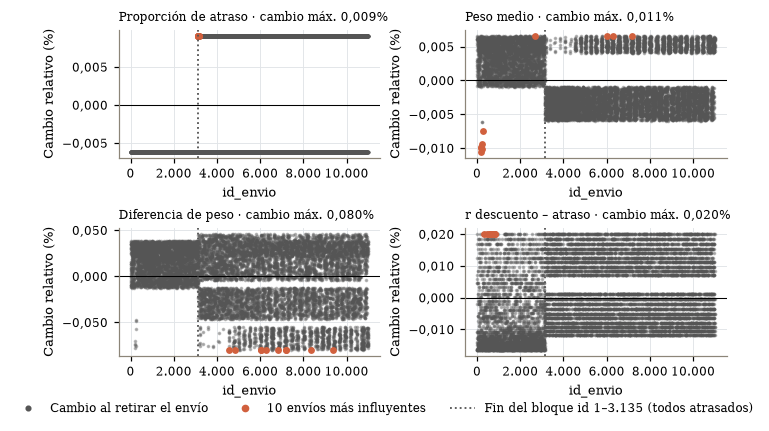

In [59]:
FIG_JK = [('PAR-1', 'Proporción de atraso', 1), ('PAR-2', 'Peso medio', 1),
          ('EFE-1', 'Diferencia de peso', 1), ('COR-1', 'r descuento – atraso', 1)]
fig, ejes = plt.subplots(2, 2, figsize=(ANCHO, 3.6))
for ax, (id_, titulo, escala) in zip(ejes.flat, FIG_JK):
    posiciones = JACKKNIFE[id_][1] if id_ in JACKKNIFE else np.arange(n)
    fila = jackknife_res.set_index('id').loc[id_]
    cambio = CAMBIOS[id_] / abs(fila['estimacion']) * 100   # cambio relativo en %
    top = np.argsort(-np.abs(cambio), kind='stable')[:10]
    ax.scatter(ids_envio[posiciones], cambio, s=2, color=GRIS, alpha=0.35, rasterized=True)
    ax.scatter(ids_envio[posiciones][top], cambio[top], s=12, color=TERRA)
    ax.axhline(0, color='black', lw=0.7)
    ax.axvline(3_135.5, color=GRIS, ls=':', lw=1.2)
    ax.set_title(f"{titulo} · cambio máx. {num(fila['cambio_max_rel'] * 100, 3)}%", fontsize=8)
    ax.set_xlabel('id_envio')
    ax.set_ylabel('Cambio relativo (%)')
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: num(v)))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: num(v, 3)))
fig.legend([Line2D([], [], color=GRIS, marker='o', ls='', ms=3), Line2D([], [], color=TERRA, marker='o', ls='', ms=4),
            Line2D([], [], color=GRIS, ls=':', lw=1.2)],
           ['Cambio al retirar el envío', '10 envíos más influyentes',
            'Fin del bloque id 1–3.135 (todos atrasados)'], loc='lower center', ncol=3,
           bbox_to_anchor=(0.5, -0.06))
guardar('fig_5_jackknife', fig)

#### Interpretación del *jackknife*

**Ningún envío individual cambia una conclusión.** Al retirar cualquiera de los 10.999 envíos:

- los parámetros cambian como máximo un 0,011 %; el mayor cambio es 0,38 g en el peso medio, al retirar el envío 200, el de mayor peso de la muestra;
- la diferencia de peso cambia un 0,08 % (0,71 g sobre −896 g);
- las correlaciones cambian a lo sumo un 0,75 %, en compras previas–atraso.

En T02 y T03, el |*t*| mínimo sin un envío es 29,26 y 54,69, y ningún envío cambia la decisión. El EE *jackknife* coincide con el *bootstrap* (razón entre 0,989 y 1,013), lo que confirma la estimación de la incertidumbre por una tercera vía. No hay valores extremos que deban eliminarse: los envíos más influyentes son valores válidos.

**El *jackknife* revela una estructura del archivo.** La figura 5 muestra un cambio de patrón en el `id_envio` 3.136, y la verificación directa lo confirma:

- los **3.135 primeros registros están todos atrasados** y contienen **todos** los envíos con descuento mayor que 10 (el último es el 3.134);
- desde el 3.136, la tasa de atraso es 43,6 % y no hay descuentos mayores que 10.

El peso medio también difiere entre los dos bloques: 2.366 g frente a 4.140 g. El segmento que S1 recomendó auditar coincide, por lo tanto, con un **bloque contiguo del archivo**. Es compatible con que esos registros provengan de otro período, sistema o regla de registro. Esto refuerza la recomendación de S1 de verificar la procedencia y la temporalidad del descuento antes de interpretarlo. Esto tambíen podría ser una señal de datos sintéticos.

### 7.2 Escenarios de extremos y composición

Las reglas se fijan antes de calcular y los umbrales se obtienen de los datos completos:

| Escenario | Regla | Qué evalúa |
|---|---|---|
| Completos | Los 10.999 envíos | Referencia (secciones 3 a 5) |
| Winsorización 1/99 | Peso y costo recortados a sus percentiles 1 y 99; mismos envíos | Influencia de los valores extremos de las variables continuas |
| Exclusión por rango intercuartílico (IQR) | Se excluye todo envío fuera de [Q1 − 1,5·IQR; Q3 + 1,5·IQR] en alguna variable cuantitativa | Dependencia de los valores atípicos según una regla habitual |
| Descuento ≤ 10 | Se retiran los 2.647 envíos con descuento mayor que 10, el segmento que S1 recomienda auditar | Si las asociaciones dependen de ese segmento |

En cada escenario se recalculan, con B = 10.000 y semillas hijas del flujo `sensibilidad_escenarios`:

- los cinco estimandos de la sección 3, con IC percentil;
- las tres pruebas de permutación;
- las cinco correlaciones, con IC *bootstrap*.

Los escenarios restringidos describen **subpoblaciones**: sus diferencias con el análisis completo indican de qué envíos depende un resultado; no son estimaciones alternativas del mismo parámetro.

In [60]:
def construir_escenarios(datos):
    escenarios = {'completos': datos}
    winsor = datos.copy()
    for v in ('peso_gramos', 'costo_producto'):
        winsor[v] = datos[v].clip(*datos[v].quantile([0.01, 0.99]))
    escenarios['winsor_01_99'] = winsor
    extremo = pd.Series(False, index=datos.index)
    for v in ('llamadas_atencion', 'costo_producto', 'compras_previas', 'descuento_ofrecido', 'peso_gramos'):
        q1, q3 = datos[v].quantile([0.25, 0.75])
        extremo |= datos[v].lt(q1 - 1.5 * (q3 - q1)) | datos[v].gt(q3 + 1.5 * (q3 - q1))
    escenarios['exclusion_iqr'] = datos.loc[~extremo]
    escenarios['descuento_le10'] = datos.loc[datos['descuento_ofrecido'].le(10)]
    return escenarios


ESCENARIOS = construir_escenarios(df)
ETIQ_ESC = {'completos': 'Completos', 'winsor_01_99': 'Winsorización 1/99', 'exclusion_iqr': 'Exclusión IQR',
            'descuento_le10': 'Descuento ≤ 10'}
assert len(ESCENARIOS['descuento_le10']) == segmento_s1.loc[False, 'size'] == 8_352
resumen_escenarios = pd.DataFrame([{'escenario': e, 'envios': len(d), 'excluidos': n - len(d),
                                    'modificados': int((d[['peso_gramos', 'costo_producto']] != df.loc[d.index, ['peso_gramos', 'costo_producto']]).any(axis=1).sum()),
                                    'tasa_atraso': d[TARGET].mean()} for e, d in ESCENARIOS.items()])

inicio = time.perf_counter()
filas_par, filas_perm, filas_cor = [], [], []
for i, (esc, datos) in enumerate(ESCENARIOS.items()):
    if esc == 'completos':   # referencia ya calculada en las secciones 3 a 5
        filas_par += [{'escenario': esc, 'id': r['id'], 'estimacion': r['estimacion_s1'], 'ic_inf': r['ic_percentil_inf'],
                       'ic_sup': r['ic_percentil_sup']} for r in bootstrap_parametros.to_dict('records')]
        filas_perm += [{'escenario': esc, **r} for r in permutaciones[['codigo', 'efecto', 'estadistico_observado', 'p_perm']].to_dict('records')]
        filas_cor += [{'escenario': esc, 'id': r['id'], 'estimacion': r['estimacion_s1'], 'ic_inf': r['ic_inf'],
                       'ic_sup': r['ic_sup']} for r in correlaciones.to_dict('records')]
        continue
    a = datos[TARGET].to_numpy(dtype=float) == 1
    rng_esc = np.random.default_rng(subflujo('sensibilidad_escenarios', i, 0))
    for id_, _, _, est, _, *_ in PARAMETROS:
        x = {'PAR-1': TARGET, 'PAR-2': 'peso_gramos', 'PAR-3': 'costo_producto', 'PAR-4': 'llamadas_atencion',
             'EFE-1': 'peso_gramos'}[id_]
        v = datos[x].to_numpy(dtype=float)
        muestras = (v[a], v[~a]) if id_ == 'EFE-1' else (v,)
        rep = bootstrap(est, muestras, rng_esc)
        filas_par.append({'escenario': esc, 'id': id_, 'estimacion': float(est(*[m[None, :] for m in muestras])[0]),
                          'ic_inf': np.quantile(rep, 0.025), 'ic_sup': np.quantile(rep, 0.975)})
    rng_esc = np.random.default_rng(subflujo('sensibilidad_escenarios', i, 1))
    for codigo in ('T01', 'T02', 'T03'):
        res, _ = permutar_contraste(datos, codigo, rng_esc)
        filas_perm.append({'escenario': esc, 'codigo': codigo, 'efecto': res['efecto'],
                           'estadistico_observado': res['estadistico_observado'], 'p_perm': res['p_perm']})
    rep = bootstrap_correlaciones(datos, np.random.default_rng(subflujo('sensibilidad_escenarios', i, 2)))
    obs = correlaciones_filas(datos, np.arange(len(datos))[None, :])[0]
    for j, (id_, *_) in enumerate(CORRELACIONES):
        filas_cor.append({'escenario': esc, 'id': id_, 'estimacion': obs[j],
                          'ic_inf': np.quantile(rep[:, j], 0.025), 'ic_sup': np.quantile(rep[:, j], 0.975)})
    print(f'{ETIQ_ESC[esc]}: {num(len(datos))} envíos ({num(time.perf_counter() - inicio, 0)} s acumulados).')

sens_parametros, sens_pruebas, sens_correlaciones = (pd.DataFrame(f) for f in (filas_par, filas_perm, filas_cor))
sens_pruebas['cota_bonferroni7'] = (7 * sens_pruebas['p_perm']).clip(upper=1)
sens_pruebas['rechaza'] = sens_pruebas['cota_bonferroni7'] <= 0.05
sens_correlaciones['incluye_cero'] = (sens_correlaciones['ic_inf'] <= 0) & (sens_correlaciones['ic_sup'] >= 0)
for tabla, clave in ((sens_parametros, 'id'), (sens_pruebas, 'codigo'), (sens_correlaciones, 'id')):
    base = tabla[tabla['escenario'] == 'completos'].set_index(clave)
    col = 'efecto' if clave == 'codigo' else 'estimacion'
    tabla['cambio_relativo'] = tabla[col] / tabla[clave].map(base[col]) - 1
for nombre, tabla in [('escenarios', resumen_escenarios), ('parametros', sens_parametros),
                      ('pruebas', sens_pruebas), ('correlaciones', sens_correlaciones)]:
    tabla.to_csv(TABLAS / f'sensibilidad_{nombre}.csv', index=False)
display(resumen_escenarios.round(4))
display(sens_parametros.pivot(index='id', columns='escenario', values='estimacion')[list(ESCENARIOS)].round(4))
display(sens_pruebas.pivot(index='codigo', columns='escenario', values=['efecto', 'p_perm'])
        .reindex(columns=list(ESCENARIOS), level=1).round(4))
display(sens_correlaciones.assign(ic=lambda d: d.apply(lambda r: f"{r.estimacion:.3f} [{r.ic_inf:.3f}; {r.ic_sup:.3f}]", axis=1))
        .pivot(index='id', columns='escenario', values='ic')[list(ESCENARIOS)])

Winsorización 1/99: 10.999 envíos (36 s acumulados).
Exclusión IQR: 7.971 envíos (61 s acumulados).
Descuento ≤ 10: 8.352 envíos (87 s acumulados).


,escenario,envios,excluidos,modificados,tasa_atraso
0,completos,10999,0,0,0.5967
1,winsor_01_99,10999,0,425,0.5967
2,exclusion_iqr,7971,3028,0,0.4952
3,descuento_le10,8352,2647,0,0.4689


escenario,completos,winsor_01_99,exclusion_iqr,descuento_le10
id,,,,
EFE-1,-896.0283,-897.3692,-449.6153,-283.7460
PAR-1,0.5967,0.5967,0.4952,0.4689
PAR-2,3634.0167,3633.1763,3956.6958,4035.6285
PAR-3,210.1968,210.2277,213.6862,214.6341
PAR-4,4.0545,4.0545,4.1330,4.1517


efecto                                              p_perm  \
escenario completos winsor_01_99 exclusion_iqr descuento_le10 completos   
codigo                                                                    
T01          0.0082       0.0082        0.0134         0.0049    0.6911   
T02       -896.0283    -897.3692     -449.6153      -283.7460    0.0001   
T03         13.1177      13.1177        0.8579        -0.0825    0.0001   

                                                     
escenario winsor_01_99 exclusion_iqr descuento_le10  
codigo                                               
T01             0.6931        0.5005         0.9013  
T02             0.0001        0.0001         0.0001  
T03             0.0001        0.0001         0.1858

escenario,completos,winsor_01_99,exclusion_iqr,descuento_le10
id,,,,
COR-1,0.397 [0.388; 0.407],0.397 [0.388; 0.406],0.121 [0.100; 0.141],-0.014 [-0.036; 0.007]
COR-2,-0.269 [-0.287; -0.251],-0.270 [-0.287; -0.251],-0.139 [-0.160; -0.117],-0.088 [-0.109; -0.066]
COR-3,-0.316 [-0.333; -0.298],-0.316 [-0.333; -0.299],-0.081 [-0.103; -0.059],0.007 [-0.015; 0.028]
COR-4,-0.074 [-0.092; -0.055],-0.074 [-0.093; -0.055],-0.010 [-0.033; 0.012],0.003 [-0.018; 0.025]
COR-5,-0.056 [-0.075; -0.037],-0.056 [-0.074; -0.037],-0.042 [-0.064; -0.020],-0.012 [-0.033; 0.010]


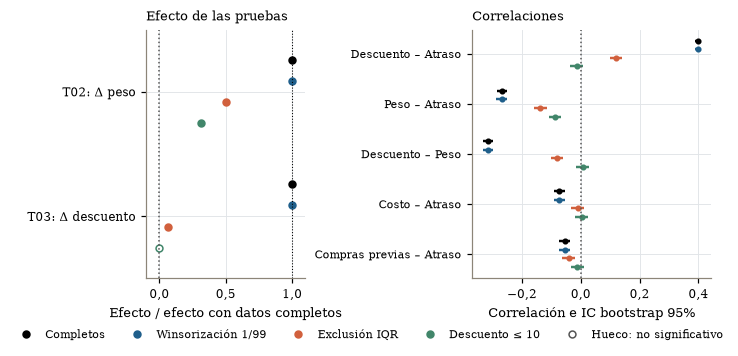

In [61]:
COLORES_ESC = {'completos': 'black', 'winsor_01_99': AZUL, 'exclusion_iqr': TERRA, 'descuento_le10': VERDE}
fig, ejes = plt.subplots(1, 2, figsize=(ANCHO, 2.9), width_ratios=[1, 1.5])
# Izquierda: efecto de T02 y T03 relativo a los datos completos; punto hueco = no significativo
codigos = ['T02', 'T03']
base_efecto = sens_pruebas.query("escenario == 'completos'").set_index('codigo')['efecto']
for j, esc in enumerate(ESCENARIOS):
    t = sens_pruebas[sens_pruebas['escenario'] == esc].set_index('codigo').loc[codigos]
    for yy, (codigo, r) in zip(np.arange(2)[::-1] + (1.5 - j) * 0.17, t.iterrows()):
        ejes[0].plot(r['efecto'] / base_efecto[codigo], yy, 'o', ms=4.5, color=COLORES_ESC[esc],
                     mfc=COLORES_ESC[esc] if r['rechaza'] else 'white')
ejes[0].axvline(1, color='black', lw=0.7, ls=':')
ejes[0].axvline(0, color=GRIS, lw=1, ls=':')
ejes[0].set_yticks([1, 0], ['T02: Δ peso', 'T03: Δ descuento'])
ejes[0].set_ylim(-0.5, 1.5)
ejes[0].set_xlim(-0.1, 1.1)
ejes[0].set_xlabel('Efecto / efecto con datos completos')
ejes[0].xaxis.set_major_formatter(FMT_NUM(1))
ejes[0].set_title('Efecto de las pruebas', fontsize=8.5)
# Derecha: correlaciones con su IC en cada escenario
ids = [c[0] for c in CORRELACIONES]
for j, esc in enumerate(ESCENARIOS):
    t = sens_correlaciones[sens_correlaciones['escenario'] == esc].set_index('id').loc[ids]
    y = np.arange(len(ids))[::-1] + (1.5 - j) * 0.17
    ejes[1].hlines(y, t['ic_inf'], t['ic_sup'], color=COLORES_ESC[esc], lw=1.6)
    ejes[1].plot(t['estimacion'], y, 'o', ms=3, color=COLORES_ESC[esc])
ejes[1].axvline(0, color=GRIS, ls=':', lw=1)
ejes[1].set_yticks(np.arange(len(ids))[::-1], correlaciones['relacion'], fontsize=7.5)
ejes[1].set_xlabel('Correlación e IC bootstrap 95%')
ejes[1].set_title('Correlaciones', fontsize=8.5)
ejes[1].xaxis.set_major_formatter(FMT_NUM(1))
fig.legend([Line2D([], [], color=c, marker='o', ls='', ms=4.5) for c in COLORES_ESC.values()]
           + [Line2D([], [], color=GRIS, marker='o', ls='', ms=4.5, mfc='white')],
           [ETIQ_ESC[e] for e in COLORES_ESC] + ['Hueco: no significativo'],
           loc='lower center', ncol=5, bbox_to_anchor=(0.5, -0.08), fontsize=7)
guardar('fig_6_escenarios', fig)

#### Interpretación de los escenarios

**Winsorización 1/99 (425 envíos modificados): todo se mantiene.** El peso medio pasa de 3.634,0 a 3.633,2 g y la diferencia de peso, de −896,0 a −897,4 g. Las correlaciones no cambian en la tercera cifra decimal y las decisiones son las mismas. Los resultados **no dependen de los valores extremos** de peso y costo.

**Exclusión IQR (7.971 envíos) y descuento ≤ 10 (8.352): la composición sí importa.**

| Resultado | Completos | Exclusión IQR | Descuento ≤ 10 |
|---|---:|---:|---:|
| Tasa de atraso | 59,7 % | 49,5 % | 46,9 % |
| Diferencia de peso (T02) | −896 g | −450 g (*p* ≤ 0,0001) | −284 g (*p* ≤ 0,0001) |
| Diferencia de descuento (T03) | 13,12 | 0,86 (*p* ≤ 0,0001) | −0,08 (*p* = 0,186) |
| r descuento – atraso | 0,397 | 0,121 | −0,014 [−0,036; 0,007] |
| r peso – atraso | −0,269 | −0,139 | −0,088 [−0,109; −0,066] |
| ρ descuento – peso | −0,316 | −0,081 | 0,007 [−0,015; 0,028] |
| r costo – atraso | −0,074 | −0,010 [−0,033; 0,012] | 0,003 [−0,018; 0,025] |
| r compras previas – atraso | −0,056 | −0,042 | −0,012 [−0,033; 0,010] |

La exclusión IQR retira sobre todo envíos con descuento alto (su límite superior es 19) y compras previas altas. Por eso actúa, en parte, como una versión parcial del escenario de descuento ≤ 10.

**Resultados robustos frente a sensibles.**

- **Robusto:** la asociación negativa del **peso** con el atraso. Conserva signo, significancia e IC alejado del cero en todos los escenarios, aunque su magnitud cae a un tercio fuera del descuento alto.
- **Sensible:** la asociación del **descuento** con el atraso **existe solo por el segmento > 10**. Al retirarlo, la diferencia de T03 deja de ser significativa y la correlación pasa a incluir el cero. Lo mismo ocurre con la relación descuento–peso, por lo que la confusión entre ambos se concentra en ese segmento.
- **Sensibles e inestables:** costo y compras previas. Sus IC incluyen el cero en los escenarios restringidos.
- **Sin asociación en ningún escenario:** la modalidad (T01, *p* entre 0,50 y 0,90).

Los escenarios restringidos describen subpoblaciones, no correcciones. La regla IQR no justifica eliminar 3.028 envíos válidos.

### 7.3 Sensibilidad del Monte Carlo

La sección 6 fija $p$ en la estimación puntual de S1 y supone que todos los envíos comparten esa probabilidad. Se cambian ambos supuestos, siempre con valores publicados en S1 (flujo `sensibilidad_montecarlo`, B = 10.000):

1. **Incertidumbre de $p$.** Se usan los extremos del IC de Wilson de S1, [58,75 %; 60,58 %], y el centro, con lotes de 1.000 envíos. Las mismas 10.000 uniformes se transforman con la inversa de la binomial de cada $p$ (*uniformes comunes*), de modo que las diferencias entre escenarios se deben a $p$ y no al ruido de la simulación.
2. **Proceso con dos segmentos.** Cada lote mantiene la composición de S1:
   - el 24,07 % de los envíos (2.647 de 10.999) tiene descuento mayor que 10 y tasa de atraso 1;
   - el resto tiene tasa 46,89 % (3.916 de 8.352).

   Este modelo representa la concentración del atraso que S1 encontró en el descuento alto.

In [62]:
rng_smc = generador('sensibilidad_montecarlo')
N_SMC = 1_000
P_ESCENARIOS = {'Wilson inferior': est_s1.loc[TARGET, 'ic_inf'], 'Estimación S1': P_S1,
                'Wilson superior': est_s1.loc[TARGET, 'ic_sup']}
u = rng_smc.random(B)
TASAS_P = {e: lotes_inversion(u, N_SMC, p) for e, p in P_ESCENARIOS.items()}
sens_p = pd.DataFrame([{'escenario': e, **resumir_lotes(TASAS_P[e], p, N_SMC, UMBRAL)} for e, p in P_ESCENARIOS.items()])

FRAC_ALTO = segmento_s1.loc[True, 'size'] / n
P_ALTO, P_BAJO = segmento_s1.loc[True, 'mean'], segmento_s1.loc[False, 'mean']
assert P_ALTO == 1.0
TASAS_SEG, filas = {}, []
for N in TAMANOS:
    n_alto = int(round(N * FRAC_ALTO))
    TASAS_SEG[N] = (rng_smc.binomial(n_alto, P_ALTO, size=B) + rng_smc.binomial(N - n_alto, P_BAJO, size=B)) / N
    t, glob = TASAS_SEG[N], montecarlo.set_index('N').loc[N]
    q = (t > UMBRAL).mean()
    filas.append({'N': N, 'n_alto': n_alto, 'media': t.mean(), 'de': t.std(ddof=1), 'de_global': glob['de'],
                  'razon_de': t.std(ddof=1) / glob['de'], 'q99': np.quantile(t, 0.99), 'q99_global': glob['q99'],
                  'prob_sobre_umbral': q, 'mcse_prob': np.sqrt(q * (1 - q) / B),
                  'prob_exacta': binom.sf(np.floor(UMBRAL * N) - n_alto, N - n_alto, P_BAJO),
                  'prob_global': glob['prob_sobre_umbral']})
sens_segmentos = pd.DataFrame(filas)
assert (sens_p['dif_prob'].abs() <= 4 * sens_p['mcse_prob']).all()
assert ((sens_segmentos['prob_sobre_umbral'] - sens_segmentos['prob_exacta']).abs() <= 4 * sens_segmentos['mcse_prob'] + 1e-12).all()
sens_p.to_csv(TABLAS / 'sensibilidad_montecarlo_p.csv', index=False)
sens_segmentos.to_csv(TABLAS / 'sensibilidad_montecarlo_segmentos.csv', index=False)
display(sens_p[['escenario', 'p', 'media', 'q025', 'q975', 'q99', 'prob_sobre_umbral', 'prob_exacta', 'mcse_prob']].round(4))
display(sens_segmentos.round(4))

,escenario,p,media,q025,q975,q99,prob_sobre_umbral,prob_exacta,mcse_prob
0,Wilson inferior,0.5875,0.5875,0.557,0.618,0.624,0.2030,0.2018,0.0040
1,Estimación S1,0.5967,0.5967,0.567,0.627,0.633,0.4067,0.4038,0.0049
2,Wilson superior,0.6058,0.6059,0.576,0.636,0.642,0.6330,0.6355,0.0048


,N,n_alto,media,de,de_global,razon_de,q99,q99_global,prob_sobre_umbral,mcse_prob,prob_exacta,prob_global
0,100,24,0.5961,0.0436,0.0491,0.8889,0.700,0.7100,0.4206,0.0049,0.4203,0.4360
1,500,120,0.5966,0.0194,0.0218,0.8916,0.642,0.6480,0.4112,0.0049,0.4050,0.4207
2,1000,241,0.5970,0.0138,0.0155,0.8909,0.628,0.6330,0.4034,0.0049,0.3957,0.3980
3,5000,1203,0.5967,0.0061,0.0069,0.8762,0.611,0.6132,0.2895,0.0045,0.2879,0.3106


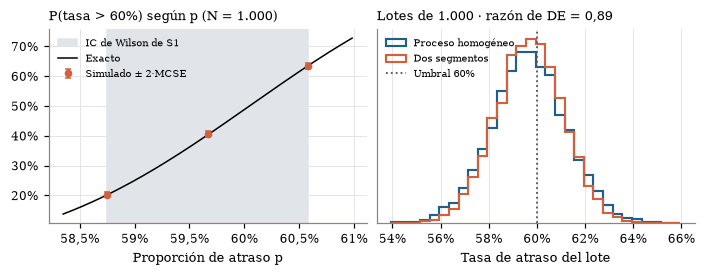

In [63]:
fig, ejes = plt.subplots(1, 2, figsize=(ANCHO, 2.4))
p_inf, p_sup = P_ESCENARIOS['Wilson inferior'], P_ESCENARIOS['Wilson superior']
rejilla_p = np.linspace(p_inf - 0.004, p_sup + 0.004, 300)
ejes[0].axvspan(p_inf, p_sup, color=GRID, label='IC de Wilson de S1')
ejes[0].plot(rejilla_p, binom.sf(np.floor(UMBRAL * N_SMC), N_SMC, rejilla_p), color='black', lw=1, label='Exacto')
ejes[0].errorbar(sens_p['p'], sens_p['prob_sobre_umbral'], yerr=2 * sens_p['mcse_prob'], fmt='o', ms=4, color=TERRA,
                 capsize=2, label='Simulado ± 2·MCSE')
ejes[0].set_title('P(tasa > 60%) según p (N = 1.000)', fontsize=8.5)
ejes[0].set_xlabel('Proporción de atraso p')
ejes[0].xaxis.set_major_formatter(FMT_PCT)
ejes[0].yaxis.set_major_formatter(FMT_PCT)
ejes[0].legend(loc='upper left', fontsize=6.5)
bordes = (np.arange(540, 664, 4) - 0.5) / 1_000
ejes[1].hist(TASAS[1_000], bins=bordes, density=True, histtype='step', color=AZUL, lw=1.4, label='Proceso homogéneo')
ejes[1].hist(TASAS_SEG[1_000], bins=bordes, density=True, histtype='step', color=TERRA, lw=1.4, label='Dos segmentos')
ejes[1].axvline(UMBRAL, color=GRIS, ls=':', lw=1.2, label='Umbral 60%')
ejes[1].set_title(f"Lotes de 1.000 · razón de DE = "
                  f"{num(sens_segmentos.set_index('N').loc[1_000, 'razon_de'], 2)}", fontsize=8.5)
ejes[1].set_xlabel('Tasa de atraso del lote')
ejes[1].xaxis.set_major_formatter(FMT_PCT)
ejes[1].set_yticks([])
ejes[1].legend(loc='upper left', fontsize=6.5)
guardar('fig_7_sensibilidad_montecarlo', fig)

#### Interpretación de la sensibilidad del Monte Carlo

| $p$ supuesto | P(tasa > 60 %), lote de 1.000 (exacta) | Percentil 99 |
|---|---:|---:|
| Wilson inferior (58,75 %) | 20,3 % (20,2 %) | 62,4 % |
| Estimación de S1 (59,67 %) | 40,7 % (40,4 %) | 63,3 % |
| Wilson superior (60,58 %) | 63,3 % (63,6 %) | 64,2 % |

**La probabilidad de superar el 60 % es muy sensible a $p$.** Como el 60 % cae dentro del IC de Wilson, esa probabilidad va de una de cada cinco a casi dos de cada tres, según el valor de $p$ compatible con los datos. Las uniformes comunes garantizan que esa diferencia se debe a $p$ y no a la simulación. En cambio, el **percentil 99** (límite de alerta) se mueve menos de un punto porcentual hacia cada lado: es una referencia más estable que un umbral fijo cercano a $p$.

**El modelo de dos segmentos reduce la dispersión.** Si cada lote mantiene la proporción de envíos con descuento > 10 de S1 (24 %, todos atrasados), solo varía el resto. La DE de la tasa del lote baja entre 10,8 % y 12,4 % (razón entre 0,88 y 0,89 en los cuatro tamaños), y el percentil 99 del lote de 1.000 pasa de 63,3 % a 62,8 %. La probabilidad exacta de superar el 60 % baja de 40,4 % a 39,6 % con 1.000 envíos, y de 31,2 % a 28,8 % con 5.000. El modelo homogéneo es, por lo tanto, levemente conservador: si la mezcla de descuentos de los lotes fuera estable, los límites de alerta podrían ser algo más estrechos. Si la mezcla varía entre lotes, como sugiere el bloque de registros de 7.1, la dispersión real sería **mayor** que la de ambos modelos.

**Conclusión.** La recomendación sobre umbrales depende de la incertidumbre de $p$ y de la composición de los lotes, no del error Monte Carlo, que es despreciable con B = 10.000.

## 8. Resultados validados e insumos para S3

La tabla reúne, para cada resultado seleccionado, su valor en S1, la evidencia de S2 y un estado:

- **respaldado**: los métodos computacionales coinciden con S1 y la conclusión se mantiene en el *jackknife* y en todos los escenarios;
- **respaldado, magnitud sensible**: la dirección o la decisión se mantienen, pero el tamaño cambia más de un 25 % en algún escenario;
- **sensible**: cambia la decisión, el signo, o el IC pasa a incluir el cero en algún escenario;
- **no concluyente**: el IC incluye el cero con los datos completos o la prueba no rechaza la hipótesis nula.

Para la proporción y las medias, los escenarios restringidos cambian la población por construcción. Su robustez frente a extremos se evalúa con el *jackknife* y la winsorización, y la composición se documenta aparte.

Se exporta a `outputs/resultados_validados.csv` y a `docs/resultados_validados.md`.

In [64]:
def estado_resultado(cambio_rel, conserva, incluye_cero_base=False):
    if incluye_cero_base:
        return 'no concluyente'
    if not conserva:
        return 'sensible'
    return 'respaldado, magnitud sensible' if np.nanmax(np.abs(cambio_rel)) > 0.25 else 'respaldado'


filas = []
jk = jackknife_res.set_index('id')
for r in bootstrap_parametros.to_dict('records'):
    sp = sens_parametros[sens_parametros['id'] == r['id']].set_index('escenario')
    restringidos = sp.loc[['exclusion_iqr', 'descuento_le10']]
    if r['id'] == 'EFE-1':
        conserva = bool(((sp['ic_sup'] < 0)).all())
        estado = estado_resultado(sp['cambio_relativo'], conserva)
    else:
        conserva = bool(abs(sp.loc['winsor_01_99', 'cambio_relativo']) < 0.01 and jk.loc[r['id'], 'cambio_max_rel'] < 0.01)
        estado = 'respaldado' if conserva else 'sensible'
    escala = 100 if r['unidad'] == '%' else 1
    filas.append({'id': r['id'], 'resultado': r['parametro'], 'familia': 'parámetro' if r['id'].startswith('PAR') else 'efecto',
                  'valor_s1': r['estimacion_s1'] * escala, 'ic_o_p_s1': f"IC {r['metodo_s1']} [{r['ic_s1_inf'] * escala:.4f}; {r['ic_s1_sup'] * escala:.4f}]",
                  'metodo_s2': 'Bootstrap percentil y BCa', 'B': r['B'],
                  'evidencia_s2': f"BCa [{r['ic_bca_inf'] * escala:.4f}; {r['ic_bca_sup'] * escala:.4f}]; ancho/S1 = {r['razon_ancho_bca']:.3f}",
                  'jackknife_cambio_max_rel': jk.loc[r['id'], 'cambio_max_rel'],
                  'sensibilidad': '; '.join(f"{ETIQ_ESC[e]}: {sp.loc[e, 'estimacion'] * escala:.4f}" for e in list(ESCENARIOS)[1:]),
                  'estado': estado})
for r in permutaciones.to_dict('records'):
    sp = sens_pruebas[sens_pruebas['codigo'] == r['codigo']].set_index('escenario')
    no_rechaza = not r['rechaza_perm']
    estado = ('no concluyente' if no_rechaza and not sp['rechaza'].any() else
              estado_resultado(sp['cambio_relativo'], bool(sp['rechaza'].all() and (np.sign(sp['efecto']) == np.sign(r['efecto'])).all())))
    filas.append({'id': r['codigo'], 'resultado': r['prueba'], 'familia': 'prueba',
                  'valor_s1': contrastes_s1[r['codigo']]['chi2' if r['codigo'] == 'T01' else 't'],
                  'ic_o_p_s1': f"p = {r['p_s1']:.3g}; Holm (7) = {r['p_s1_holm7']:.3g}",
                  'metodo_s2': 'Permutación', 'B': r['B'],
                  'evidencia_s2': f"p perm. = {r['p_perm']:.5f} ({r['excedencias']} excedencias); cota de Bonferroni (7) = {r['cota_bonferroni7_perm']:.4f}",
                  'jackknife_cambio_max_rel': np.nan,
                  'sensibilidad': '; '.join(f"{ETIQ_ESC[e]}: efecto {sp.loc[e, 'efecto']:.3f}, p perm. {sp.loc[e, 'p_perm']:.4f}"
                                            for e in list(ESCENARIOS)[1:]),
                  'estado': estado})
for r in correlaciones.to_dict('records'):
    sp = sens_correlaciones[sens_correlaciones['id'] == r['id']].set_index('escenario')
    conserva = bool((~sp['incluye_cero']).all() and (np.sign(sp['estimacion']) == np.sign(r['estimacion_s1'])).all())
    filas.append({'id': r['id'], 'resultado': f"{r['coeficiente']} {r['relacion']}", 'familia': 'correlación',
                  'valor_s1': r['estimacion_s1'], 'ic_o_p_s1': 'sin IC en S1 (solo p)',
                  'metodo_s2': 'Bootstrap emparejado percentil', 'B': r['B'],
                  'evidencia_s2': f"IC [{r['ic_inf']:.4f}; {r['ic_sup']:.4f}]; EE/|r| = {r['variabilidad_relativa']:.3f}",
                  'jackknife_cambio_max_rel': jk.loc[r['id'], 'cambio_max_rel'],
                  'sensibilidad': '; '.join(f"{ETIQ_ESC[e]}: {sp.loc[e, 'estimacion']:.3f} [{sp.loc[e, 'ic_inf']:.3f}; {sp.loc[e, 'ic_sup']:.3f}]"
                                            for e in list(ESCENARIOS)[1:]),
                  'estado': estado_resultado(sp['cambio_relativo'], conserva, r['incluye_cero'])})
fila_mc = montecarlo.set_index('N').loc[1_000]
filas.append({'id': 'MC-1', 'resultado': 'Tasa de atraso en lotes de 1.000 envíos', 'familia': 'simulación',
              'valor_s1': P_S1 * 100, 'ic_o_p_s1': f"IC Wilson [{P_ESCENARIOS['Wilson inferior'] * 100:.4f}; {P_ESCENARIOS['Wilson superior'] * 100:.4f}]",
              'metodo_s2': 'Monte Carlo binomial', 'B': int(fila_mc['B']),
              'evidencia_s2': f"rango 95 % [{fila_mc['q025'] * 100:.1f}; {fila_mc['q975'] * 100:.1f}] %; percentil 99 = {fila_mc['q99'] * 100:.1f} %; P(>60 %) = {fila_mc['prob_sobre_umbral']:.3f}",
              'jackknife_cambio_max_rel': np.nan,
              'sensibilidad': '; '.join([f"P(>60 %) con p = {e}: {r['prob_sobre_umbral']:.3f}" for e, r in sens_p.set_index('escenario').iterrows()]
                                        + [f"DE dos segmentos / homogéneo = {sens_segmentos.set_index('N').loc[1_000, 'razon_de']:.2f}"]),
              'estado': 'sensible'})
resultados_validados = pd.DataFrame(filas)

In [65]:
RECOMENDACION = {
    'PAR-1': 'Usar 59,67 % [58,75; 60,58] como tasa de referencia; reportar por segmento de descuento.',
    'PAR-2': 'Media válida como resumen, pero el peso es bimodal: modelar con tramos o términos no lineales.',
    'PAR-3': 'Variable de bajo poder explicativo para el atraso; conservar solo como control.',
    'PAR-4': 'Media estable; las llamadas pueden ser posteriores al envío: revisar su temporalidad antes de usarlas como predictor.',
    'EFE-1': 'Incluir el peso en S3; su efecto se reduce fuera del descuento alto: estimar interacción peso × segmento.',
    'T01': 'No priorizar la modalidad de envío; no rechazar no demuestra igualdad.',
    'T02': 'Asociación peso–atraso robusta en dirección; reportar el tamaño por segmento.',
    'T03': 'La diferencia de descuento depende del segmento > 10 (ids 1 a 3.134): auditar su procedencia antes de modelar.',
    'COR-1': 'La asociación existe solo por el segmento > 10, todo atrasado y contenido en los 3.135 primeros registros; modelarlo aparte (separación completa).',
    'COR-2': 'Conservar el peso: la única correlación que excluye el cero en todos los escenarios.',
    'COR-3': 'Descuento y peso están relacionados: modelarlos conjuntamente para evitar confusión.',
    'COR-4': 'Correlación débil y sensible: no fundamentar decisiones en ella.',
    'COR-5': 'Correlación débil y sensible: no fundamentar decisiones en ella.',
    'MC-1': 'Fijar límites de alerta por tamaño de lote y en relación con el IC de p; segmentar por descuento.',
}
resultados_validados['recomendacion_s3'] = resultados_validados['id'].map(RECOMENDACION)
resultados_validados['semilla'] = SEMILLA
resultados_validados['notebook'] = 'sumativa_2/notebooks/sumativa_2_grupo1.ipynb'
assert resultados_validados['recomendacion_s3'].notna().all() and resultados_validados['id'].is_unique
resultados_validados.to_csv(RAIZ / 'outputs/resultados_validados.csv', index=False)


def tabla_md(d):
    filas_md = ['| ' + ' | '.join(d.columns) + ' |', '|' + '---|' * len(d.columns)]
    filas_md += ['| ' + ' | '.join(str(v).replace('|', '/') for v in r) + ' |' for r in d.itertuples(index=False)]
    return '\n'.join(filas_md)


vista = resultados_validados.assign(valor_s1=resultados_validados['valor_s1'].map(lambda v: f'{v:.4f}'))
texto = '\n\n'.join([
    '# Resultados validados — Sumativa 2 (S2), grupo 1',
    f'Generado por `sumativa_2/notebooks/sumativa_2_grupo1.ipynb` con la semilla {SEMILLA} y B = {B:,} réplicas en cada técnica.'.replace(',', '.'),
    '## Estado de cada resultado',
    tabla_md(vista[['id', 'resultado', 'valor_s1', 'metodo_s2', 'evidencia_s2', 'estado']]),
    '## Sensibilidad',
    tabla_md(vista[['id', 'sensibilidad']]),
    '## Recomendaciones para la Sumativa 3 (S3)',
    tabla_md(vista[['id', 'recomendacion_s3']]),
    '## Síntesis\n\nLa conclusión más robusta de la Sumativa 1 es la asociación negativa del peso con el atraso, que se mantiene en todos los métodos y escenarios. La asociación del descuento depende por completo del segmento con descuento mayor que 10, que coincide con los 3.135 primeros registros del archivo, todos atrasados. Los parámetros y sus intervalos se confirman con *bootstrap*, BCa y *jackknife*. Las pruebas de permutación reproducen las decisiones de la Sumativa 1. La simulación Monte Carlo muestra que un umbral de 60 % de atraso por lote se superaría con frecuencia solo por azar.\n',
])
(RAIZ / 'docs/resultados_validados.md').write_text(texto.rstrip() + '\n', encoding='utf-8')
display(resultados_validados[['id', 'resultado', 'estado', 'evidencia_s2']])

,id,resultado,estado,evidencia_s2
0,PAR-1,Proporción de atraso,respaldado,BCa [58.7508; 60.5873]; ancho/S1 = 1.002
1,PAR-2,Peso medio,respaldado,BCa [3602.7570; 3665.2821]; ancho/S1 = 1.023
2,PAR-3,Costo medio,respaldado,BCa [209.3138; 211.1132]; ancho/S1 = 1.002
3,PAR-4,Llamadas medias,respaldado,BCa [4.0337; 4.0755]; ancho/S1 = 0.978
4,EFE-1,Diferencia de peso medio (atrasado − puntual),"respaldado, magnitud sensible",BCa [-955.4048; -836.5055]; ancho/S1 = 0.991
5,T01,Prueba χ² de independencia entre modalidad de ...,no concluyente,p perm. = 0.69113 (6911 excedencias); cota de ...
6,T02,Prueba t de Welch de peso medio entre envíos a...,"respaldado, magnitud sensible",p perm. = 0.00010 (0 excedencias); cota de Bon...
7,T03,Prueba t de Welch de descuento medio entre env...,sensible,p perm. = 0.00010 (0 excedencias); cota de Bon...
8,COR-1,r punto-biserial Descuento – Atraso,sensible,IC [0.3879; 0.4065]; EE/|r| = 0.012
9,COR-2,r punto-biserial Peso – Atraso,"respaldado, magnitud sensible",IC [-0.2867; -0.2509]; EE/|r| = 0.034


#### Síntesis y recomendaciones para S3

**Resultados validados.**

- **Respaldados:** los cuatro parámetros de S1, con IC que coinciden con *bootstrap*, BCa y *jackknife*, sin influencia de envíos individuales ni de valores extremos.
- **Respaldados, con magnitud sensible:** la diferencia de peso y la prueba T02, junto con la correlación peso–atraso. La asociación negativa del peso con el atraso es **la conclusión más robusta** de S1.
- **Sensibles:**
  - T03 y la correlación descuento–atraso: dependen por completo del segmento con descuento > 10;
  - la relación descuento–peso;
  - las correlaciones débiles de costo y compras previas.
- **No concluyente:** la modalidad de envío (T01), sin evidencia de asociación con ningún método ni escenario.
- **Monte Carlo:** las alertas por lote dependen de la incertidumbre de $p$ y de la composición por descuento.

**Recomendaciones metodológicas para S3.**

1. **Verificar la procedencia de los 3.135 primeros registros** antes de modelar. Concentran todo el atraso con descuento > 10 y difieren en peso. Si son un bloque de otro origen, deben modelarse por separado o con una variable indicadora.
2. **Modelar por segmento de descuento**, o con interacción. En el segmento > 10 hay separación completa (atraso 100 %), lo que impide estimar una regresión logística estándar; conviene penalizar o tratar ese segmento aparte.
3. **Conservar el peso** como predictor principal, con términos no lineales por su bimodalidad, y modelarlo junto con el descuento.
4. **No excluir envíos por la regla IQR** ni winsorizar: no cambia las conclusiones y altera la población.
5. **Fijar límites de alerta por tamaño de lote** según el percentil 99 simulado, revisándolos con el IC de $p$ y por segmento.
6. **Mantener remuestreo y permutación como validación.** Evaluar la dependencia por bodega o período, por ejemplo con *bootstrap* por bloques, si se obtienen esas variables.

In [66]:
metadatos = dict(semilla=SEMILLA, pulso=registro_semilla['pulso']['uri'], flujos={f: list(s.spawn_key) for f, s in SEMILLAS_FLUJO.items()},
                 B=B, sha256_datos=HUELLA_DATOS, tablas_s1=HUELLAS_S1, versiones=VERSIONES,
                 sha256_lock=hashlib.sha256((RAIZ.parent / 'uv.lock').read_bytes().replace(b'\r\n', b'\n')).hexdigest())
(TABLAS / 'metadatos_ejecucion.json').write_text(json.dumps(metadatos, ensure_ascii=False, indent=2), encoding='utf-8')
assert hashlib.sha256(DATOS.read_bytes()).hexdigest() == HUELLA_DATOS, 'Los datos cambiaron durante la ejecución.'
print('Metadatos registrados:', ', '.join(f'{k} {v}' for k, v in VERSIONES.items()))

Metadatos registrados: python 3.14.4, numpy 2.5.3, pandas 3.0.6, scipy 1.18.1
